# Mortality24 frequency-transfer and cross-hospital experiments

This notebook visualizes final YAIB `Mortality24` test metrics for LSTM, GRU-D, and Transformer models across HiRID and MIMIC-IV at 1h, 15min, and 5min frequencies. It reads metric summaries only; it does not read patient data, train models, or evaluate models. Figures are displayed inline and saved as PNGs under `notebooks/figures/`.

Temporary `tmp*` tuning directories are excluded before run selection and evaluation counting. Metrics and standard deviations are taken directly from YAIB's `accumulated_test_metrics.json`.

## 1. Overview

Ordinary runs train and test on the same dataset. Evaluation-only runs live under `_from_*` directories: the outer dataset is the test dataset and the `_from_*` dataset is the training dataset. The notebook selects one final run per `(model, train dataset, test dataset)` configuration, preferring an ordinary matched baseline when a redundant evaluation-only result exists.

## 2. Imports and configuration

In [1]:
%matplotlib inline
import json
import math
import re
import warnings
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

LOG_ROOT = Path('/heinz-georgenas/users/mingzhul/Simultaneous-EHR/yaib/logs')
FIGURE_DIR = Path('/home/mingzhul/projects/Simultaneous-EHR/repos/YAIB/notebooks/figures')
TASK = 'Mortality24'
MODELS = ['LSTM', 'GRUD', 'Transformer']
MODEL_LABELS = {'LSTM': 'LSTM', 'GRUD': 'GRU-D', 'Transformer': 'Transformer'}
DATASETS = ['hirid', 'hirid_15min', 'hirid_5min', 'miiv', 'miiv_15min', 'miiv_5min']
FREQUENCIES = ['1h', '15min', '5min']
HOSPITALS = ['HiRID', 'MIMIC-IV']
METRICS = {'AUROC': ('AUC', 'AUROC'), 'AUPRC': ('PR', 'AUPRC')}
HOSPITAL_COLORS = {'HiRID': '#0072B2', 'MIMIC-IV': '#D55E00'}
MODEL_COLORS = {'LSTM': '#0072B2', 'GRUD': '#009E73', 'Transformer': '#CC79A7'}
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10})

assert LOG_ROOT.is_dir(), f'Logs directory not found: {LOG_ROOT}'
print(f'Using metric root: {LOG_ROOT}')

Using metric root: /heinz-georgenas/users/mingzhul/Simultaneous-EHR/yaib/logs


## 3. Discover and parse final results

The parser ignores every metric file below a directory whose name starts with `tmp`. This removes temporary hyperparameter-tuning outputs before any selection or completeness calculation.

In [2]:
TIMESTAMP_RE = re.compile(r'^\d{4}-\d{2}-\d{2}T\d{2}-\d{2}-\d{2}$')
DATASET_INFO = {
    'hirid': ('HiRID', '1h'),
    'hirid_15min': ('HiRID', '15min'),
    'hirid_5min': ('HiRID', '5min'),
    'miiv': ('MIMIC-IV', '1h'),
    'miiv_15min': ('MIMIC-IV', '15min'),
    'miiv_5min': ('MIMIC-IV', '5min'),
}

def has_temporary_component(path):
    rel = path.relative_to(LOG_ROOT)
    return any(part.startswith('tmp') for part in rel.parts[:-1])

def timestamp_from_name(name):
    if not TIMESTAMP_RE.fullmatch(name):
        return None
    return datetime.strptime(name, '%Y-%m-%dT%H-%M-%S')

def dataset_info(name):
    if name not in DATASET_INFO:
        raise ValueError(f'Unexpected dataset directory: {name}')
    hospital, frequency = DATASET_INFO[name]
    return {'dataset': name, 'hospital': hospital, 'frequency': frequency}

def parse_metric_path(metric_path):
    rel = metric_path.relative_to(LOG_ROOT)
    if len(rel.parts) < 5 or rel.name != 'accumulated_test_metrics.json':
        return None
    outer, task, model = rel.parts[:3]
    if task != TASK or model not in MODELS or outer not in DATASETS:
        return None
    timestamp_index = next((i for i, part in enumerate(rel.parts) if TIMESTAMP_RE.fullmatch(part)), None)
    if timestamp_index is None or timestamp_index < 3:
        return None
    prefix = rel.parts[3:timestamp_index]
    if len(prefix) > 1 or (prefix and not prefix[0].startswith('_from_')):
        return None
    outer_info = dataset_info(outer)
    evaluation_only = bool(prefix)
    train_dataset = prefix[0][len('_from_'):] if evaluation_only else outer
    if train_dataset not in DATASETS:
        raise ValueError(f'Unexpected source dataset in {metric_path}: {train_dataset}')
    run_timestamp = rel.parts[timestamp_index]
    run_dir = LOG_ROOT.joinpath(*rel.parts[:timestamp_index + 1])
    return {
        'model_key': model,
        'model': MODEL_LABELS[model],
        'train_dataset_key': train_dataset,
        'test_dataset_key': outer,
        'train_hospital': dataset_info(train_dataset)['hospital'],
        'train_frequency': dataset_info(train_dataset)['frequency'],
        'test_hospital': outer_info['hospital'],
        'test_frequency': outer_info['frequency'],
        'evaluation_only': evaluation_only,
        'timestamp': run_timestamp,
        'timestamp_dt': timestamp_from_name(run_timestamp),
        'run_dir': run_dir,
        'json_path': metric_path,
    }

all_metric_paths = sorted(LOG_ROOT.rglob('accumulated_test_metrics.json'))
temporary_metric_paths = [p for p in all_metric_paths if has_temporary_component(p)]
eligible_metric_paths = [p for p in all_metric_paths if not has_temporary_component(p)]
candidates = []
parse_warnings = []
for path in eligible_metric_paths:
    try:
        parsed = parse_metric_path(path)
        if parsed is not None:
            candidates.append(parsed)
    except Exception as exc:
        parse_warnings.append(f'{path}: {type(exc).__name__}: {exc}')

candidate_groups = defaultdict(list)
for candidate in candidates:
    key = (candidate['model_key'], candidate['train_dataset_key'], candidate['test_dataset_key'])
    candidate_groups[key].append(candidate)

print(f'Discovered accumulated metric files: {len(all_metric_paths)}')
print(f'Excluded temporary tuning files: {len(temporary_metric_paths)}')
print(f'Eligible final metric files: {len(candidates)}')
if parse_warnings:
    print('Parser warnings:')
    for message in parse_warnings:
        print(' -', message)

Discovered accumulated metric files: 152
Excluded temporary tuning files: 2
Eligible final metric files: 150


## 4. Select the most recent final experiment

Metric means and standard deviations are read directly from the selected JSON. YAIB's original `std` values are preserved exactly; no correction, scaling, or recomputation is applied.

In [3]:
def finite_number(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return np.nan
    return value if math.isfinite(value) else np.nan

def read_metric_summary(candidate):
    with candidate['json_path'].open() as handle:
        payload = json.load(handle)
    if not isinstance(payload, dict) or not isinstance(payload.get('avg'), dict):
        raise ValueError('missing avg metric object')
    if finite_number(payload['avg'].get('AUC')) != finite_number(payload['avg'].get('AUC')):
        raise ValueError('missing or invalid avg.AUC')
    if finite_number(payload['avg'].get('PR')) != finite_number(payload['avg'].get('PR')):
        raise ValueError('missing or invalid avg.PR')
    std = payload.get('std', {}) if isinstance(payload.get('std', {}), dict) else {}
    return {
        'AUROC mean': finite_number(payload['avg'].get('AUC')),
        'AUROC std': finite_number(std.get('AUC')),
        'AUPRC mean': finite_number(payload['avg'].get('PR')),
        'AUPRC std': finite_number(std.get('PR')),
    }

def count_evaluations(run_dir):
    aggregate_path = run_dir / 'aggregated_test_metrics.json'
    if aggregate_path.exists():
        try:
            payload = json.loads(aggregate_path.read_text())
            count = sum(
                1
                for repetition, folds in payload.items()
                if repetition.startswith('repetition_') and isinstance(folds, dict)
                for fold, metrics in folds.items()
                if fold.startswith('fold_') and isinstance(metrics, dict)
            )
            if count:
                return count, 'aggregated_test_metrics.json'
        except Exception as exc:
            selection_warnings.append(f'{aggregate_path}: {type(exc).__name__}: {exc}; using fold files')
    fold_keys = set()
    for path in run_dir.rglob('test_metrics.json'):
        if has_temporary_component(path):
            continue
        parts = path.relative_to(run_dir).parts
        repetition = next((part for part in parts if part.startswith('repetition_')), None)
        fold = next((part for part in parts if part.startswith('fold_')), None)
        if repetition and fold:
            fold_keys.add((repetition, fold))
    return len(fold_keys), 'fold metric files'

selection_warnings = []
selected = []
selection_rows = []
for key, group in sorted(candidate_groups.items()):
    group = sorted(group, key=lambda item: item['timestamp_dt'], reverse=True)
    ordinary = [item for item in group if not item['evaluation_only']]
    eligible_group = ordinary if key[1] == key[2] and ordinary else group
    redundant = [item for item in group if item not in eligible_group]
    chosen = None
    invalid = []
    for candidate in eligible_group:
        try:
            summary = read_metric_summary(candidate)
            chosen = {**candidate, **summary}
            break
        except Exception as exc:
            invalid.append(candidate)
            selection_warnings.append(str(candidate['json_path']) + ': ' + type(exc).__name__ + ': ' + str(exc))
    if chosen is not None:
        evaluations, count_source = count_evaluations(chosen['run_dir'])
        chosen['evaluations'] = evaluations
        chosen['evaluation_count_source'] = count_source
        chosen['complete'] = evaluations == 25
        selected.append(chosen)
    else:
        evaluations, count_source = np.nan, 'unavailable'
    selection_rows.append({
        'Model': MODEL_LABELS[key[0]],
        'Train dataset': key[1],
        'Test dataset': key[2],
        'Candidate runs': len(group),
        'Eligible final runs': len(eligible_group),
        'Selected timestamp': chosen['timestamp'] if chosen else None,
        'Selected path': str(chosen['json_path']) if chosen else None,
        'Redundant runs': ', '.join(item['timestamp'] for item in redundant),
        'Invalid eligible runs': ', '.join(item['timestamp'] for item in invalid),
    })

selected_df = pd.DataFrame(selected)
if not selected_df.empty:
    selected_df = selected_df.sort_values(['model_key', 'train_dataset_key', 'test_dataset_key']).reset_index(drop=True)

result_records = []
for item in selected:
    result_records.append({
        'Model': item['model'],
        'Train hospital': item['train_hospital'],
        'Train frequency': item['train_frequency'],
        'Test hospital': item['test_hospital'],
        'Test frequency': item['test_frequency'],
        'AUROC mean': item['AUROC mean'],
        'AUROC std': item['AUROC std'],
        'AUPRC mean': item['AUPRC mean'],
        'AUPRC std': item['AUPRC std'],
        'Number of evaluations': item['evaluations'],
        'Complete/incomplete': 'Complete' if item['complete'] else 'Incomplete',
        'Experiment timestamp': item['timestamp'],
        'JSON path': str(item['json_path']),
        '_model_key': item['model_key'],
        '_train_dataset_key': item['train_dataset_key'],
        '_test_dataset_key': item['test_dataset_key'],
    })
results_df = pd.DataFrame(result_records)
DISPLAY_COLUMNS = ['Model', 'Train hospital', 'Train frequency', 'Test hospital', 'Test frequency', 'AUROC mean', 'AUROC std', 'AUPRC mean', 'AUPRC std', 'Number of evaluations', 'Complete/incomplete', 'Experiment timestamp', 'JSON path']
if not results_df.empty:
    results_df = results_df.sort_values(['_model_key', '_train_dataset_key', '_test_dataset_key']).reset_index(drop=True)

print(f'Selected configurations: {len(results_df)}')
complete_count = int((results_df['Complete/incomplete'] == 'Complete').sum()) if not results_df.empty else 0
incomplete_count = int((results_df['Complete/incomplete'] == 'Incomplete').sum()) if not results_df.empty else 0
print(f'Complete: {complete_count}; incomplete: {incomplete_count}')
if selection_warnings:
    print('Selection and fallback warnings:')
    for message in selection_warnings:
        print(' -', message)

Selected configurations: 78
Complete: 11; incomplete: 67


## 5. Data validation and completeness

In [4]:
display(results_df[DISPLAY_COLUMNS])

duplicate_summary = pd.DataFrame([row for row in selection_rows if row['Candidate runs'] > 1])
print('Duplicate and selection summary')
display(duplicate_summary if not duplicate_summary.empty else pd.DataFrame({'Status': ['No duplicate final runs']}))

summary_df = pd.DataFrame({
    'Quantity': [
        len(all_metric_paths),
        len(temporary_metric_paths),
        len(candidates),
        len(candidate_groups),
        sum(max(0, len(group) - 1) for group in candidate_groups.values()),
        int((results_df['Complete/incomplete'] == 'Complete').sum()) if not results_df.empty else 0,
        int((results_df['Complete/incomplete'] == 'Incomplete').sum()) if not results_df.empty else 0,
    ]
}, index=['Total discovered metric files', 'Temporary tuning files excluded', 'Eligible final metric files', 'Distinct configurations', 'Older/redundant eligible candidates', 'Complete selected evaluations', 'Incomplete selected evaluations'])
display(summary_df)

expected_keys = {(model, train, test) for model in MODELS for train in DATASETS for test in DATASETS}
selected_keys = {(row['_model_key'], row['_train_dataset_key'], row['_test_dataset_key']) for _, row in results_df.iterrows()}
missing_keys = sorted(expected_keys - selected_keys)
missing_df = pd.DataFrame([{'Model': MODEL_LABELS[m], 'Train dataset': train, 'Test dataset': test} for m, train, test in missing_keys])
print(f'Missing expected configurations: {len(missing_df)}')
display(missing_df if not missing_df.empty else pd.DataFrame({'Status': ['No missing configurations']}))

coverage_rows = []
for model in MODELS:
    for train_hospital in HOSPITALS:
        for test_hospital in HOSPITALS:
            available = sum(
                1 for _, row in results_df.iterrows()
                if row['_model_key'] == model and row['Train hospital'] == train_hospital and row['Test hospital'] == test_hospital
            )
            coverage_rows.append({'Model': MODEL_LABELS[model], 'Train hospital': train_hospital, 'Test hospital': test_hospital, 'Available': available, 'Expected': 9})
coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df)

# Sanity checks are advisory: newer runs may legitimately replace historical values.
sanity_targets = [
    ('LSTM', 'hirid', 'hirid', 0.8407),
    ('LSTM', 'miiv', 'miiv', 0.8667),
    ('LSTM', 'hirid', 'miiv', 0.8202),
    ('Transformer', 'hirid', 'hirid_5min', 0.7872),
]
sanity_rows = []
for model, train, test, historical in sanity_targets:
    matches = [item for item in selected if item['model_key'] == model and item['train_dataset_key'] == train and item['test_dataset_key'] == test]
    sanity_rows.append({'Configuration': f'{model}: {train} → {test}', 'Historical AUROC': historical, 'Selected AUROC': matches[0]['AUROC mean'] if matches else np.nan, 'Difference': matches[0]['AUROC mean'] - historical if matches else np.nan})
display(pd.DataFrame(sanity_rows))

,Model,Train hospital,Train frequency,Test hospital,Test frequency,AUROC mean,AUROC std,AUPRC mean,AUPRC std,Number of evaluations,Complete/incomplete,Experiment timestamp,JSON path
0,GRU-D,HiRID,1h,HiRID,1h,0.843359,0.001839,0.376266,0.004006,25,Complete,2026-10-29T13-30-50,/heinz-georgenas/users/mingzhul/Simultaneous-E...
1,GRU-D,HiRID,1h,HiRID,15min,0.834452,0.000000,0.345518,0.000000,1,Incomplete,2026-11-09T23-34-43,/heinz-georgenas/users/mingzhul/Simultaneous-E...
2,GRU-D,HiRID,1h,HiRID,5min,0.835246,0.000000,0.344712,0.000000,1,Incomplete,2026-11-09T23-35-16,/heinz-georgenas/users/mingzhul/Simultaneous-E...
3,GRU-D,HiRID,1h,MIMIC-IV,1h,0.774809,0.000000,0.264231,0.000000,1,Incomplete,2026-11-10T12-49-45,/heinz-georgenas/users/mingzhul/Simultaneous-E...
4,GRU-D,HiRID,1h,MIMIC-IV,15min,0.739583,0.000000,0.239271,0.000000,1,Incomplete,2026-11-09T23-36-22,/heinz-georgenas/users/mingzhul/Simultaneous-E...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,Transformer,MIMIC-IV,1h,HiRID,15min,0.733510,0.000000,0.253977,0.000000,1,Incomplete,2026-11-10T00-33-12,/heinz-georgenas/users/mingzhul/Simultaneous-E...
74,Transformer,MIMIC-IV,1h,HiRID,5min,0.708115,0.000000,0.217411,0.000000,1,Incomplete,2026-11-10T00-33-27,/heinz-georgenas/users/mingzhul/Simultaneous-E...
75,Transformer,MIMIC-IV,1h,MIMIC-IV,1h,0.870506,0.001001,0.413437,0.005385,25,Complete,2026-11-02T00-27-19,/heinz-georgenas/users/mingzhul/Simultaneous-E...
76,Transformer,MIMIC-IV,1h,MIMIC-IV,15min,0.786987,0.000000,0.290810,0.000000,1,Incomplete,2026-11-10T00-34-06,/heinz-georgenas/users/mingzhul/Simultaneous-E...


Duplicate and selection summary


,Model,Train dataset,Test dataset,Candidate runs,Eligible final runs,Selected timestamp,Selected path,Redundant runs,Invalid eligible runs
0,GRU-D,hirid,hirid,4,2,2026-10-29T13-30-50,/heinz-georgenas/users/mingzhul/Simultaneous-E...,"2026-11-10T00-42-12, 2026-11-03T15-15-48",
1,GRU-D,hirid,hirid_15min,3,3,2026-11-09T23-34-43,/heinz-georgenas/users/mingzhul/Simultaneous-E...,,
2,GRU-D,hirid,hirid_5min,3,3,2026-11-09T23-35-16,/heinz-georgenas/users/mingzhul/Simultaneous-E...,,
3,GRU-D,hirid,miiv,2,2,2026-11-10T12-49-45,/heinz-georgenas/users/mingzhul/Simultaneous-E...,,
4,GRU-D,hirid_15min,hirid,2,2,2026-11-10T12-51-34,/heinz-georgenas/users/mingzhul/Simultaneous-E...,,
...,...,...,...,...,...,...,...,...,...
58,Transformer,miiv,hirid_15min,2,2,2026-11-10T00-33-12,/heinz-georgenas/users/mingzhul/Simultaneous-E...,,
59,Transformer,miiv,hirid_5min,2,2,2026-11-10T00-33-27,/heinz-georgenas/users/mingzhul/Simultaneous-E...,,
60,Transformer,miiv,miiv,2,1,2026-11-02T00-27-19,/heinz-georgenas/users/mingzhul/Simultaneous-E...,2026-11-10T00-46-58,
61,Transformer,miiv,miiv_15min,2,2,2026-11-10T00-34-06,/heinz-georgenas/users/mingzhul/Simultaneous-E...,,


,Quantity
Total discovered metric files,152
Temporary tuning files excluded,2
Eligible final metric files,150
Distinct configurations,78
Older/redundant eligible candidates,72
Complete selected evaluations,11
Incomplete selected evaluations,67


Missing expected configurations: 30


,Model,Train dataset,Test dataset
0,GRU-D,miiv_15min,hirid
1,GRU-D,miiv_15min,hirid_15min
2,GRU-D,miiv_15min,hirid_5min
3,GRU-D,miiv_15min,miiv
4,GRU-D,miiv_15min,miiv_15min
5,GRU-D,miiv_15min,miiv_5min
6,GRU-D,miiv_5min,hirid
7,GRU-D,miiv_5min,hirid_15min
8,GRU-D,miiv_5min,hirid_5min
9,GRU-D,miiv_5min,miiv


,Model,Train hospital,Test hospital,Available,Expected
0,LSTM,HiRID,HiRID,9,9
1,LSTM,HiRID,MIMIC-IV,9,9
2,LSTM,MIMIC-IV,HiRID,6,9
3,LSTM,MIMIC-IV,MIMIC-IV,6,9
4,GRU-D,HiRID,HiRID,9,9
5,GRU-D,HiRID,MIMIC-IV,9,9
6,GRU-D,MIMIC-IV,HiRID,3,9
7,GRU-D,MIMIC-IV,MIMIC-IV,3,9
8,Transformer,HiRID,HiRID,9,9
9,Transformer,HiRID,MIMIC-IV,9,9


,Configuration,Historical AUROC,Selected AUROC,Difference
0,LSTM: hirid → hirid,0.8407,0.840700,4.547119e-07
1,LSTM: miiv → miiv,0.8667,0.866700,-4.784584e-07
2,LSTM: hirid → miiv,0.8202,0.813918,-6.282363e-03
3,Transformer: hirid → hirid_5min,0.7872,0.753013,-3.418693e-02


In [5]:
# Lightweight correctness checks for the parser and selection logic.
assert not any(has_temporary_component(item['json_path']) for item in selected)
assert len(selected_keys) == len(selected)
assert all(row['Train frequency'] in FREQUENCIES and row['Test frequency'] in FREQUENCIES for _, row in results_df.iterrows())
for item in selected:
    if item['train_dataset_key'] == item['test_dataset_key']:
        assert not item['evaluation_only'], 'Ordinary baseline was not preferred'
assert not any(item['model_key'] == 'GRUD' and item['train_dataset_key'] == 'hirid' and item['test_dataset_key'] == 'hirid' and item['evaluation_only'] for item in selected)
print('Parser and selection checks passed.')

Parser and selection checks passed.


## 6. Fixed-test-set line plots

Each figure fixes the test hospital and frequency by subplot, then compares training frequencies for HiRID-trained and MIMIC-IV-trained models. Hollow markers denote incomplete final evaluations.

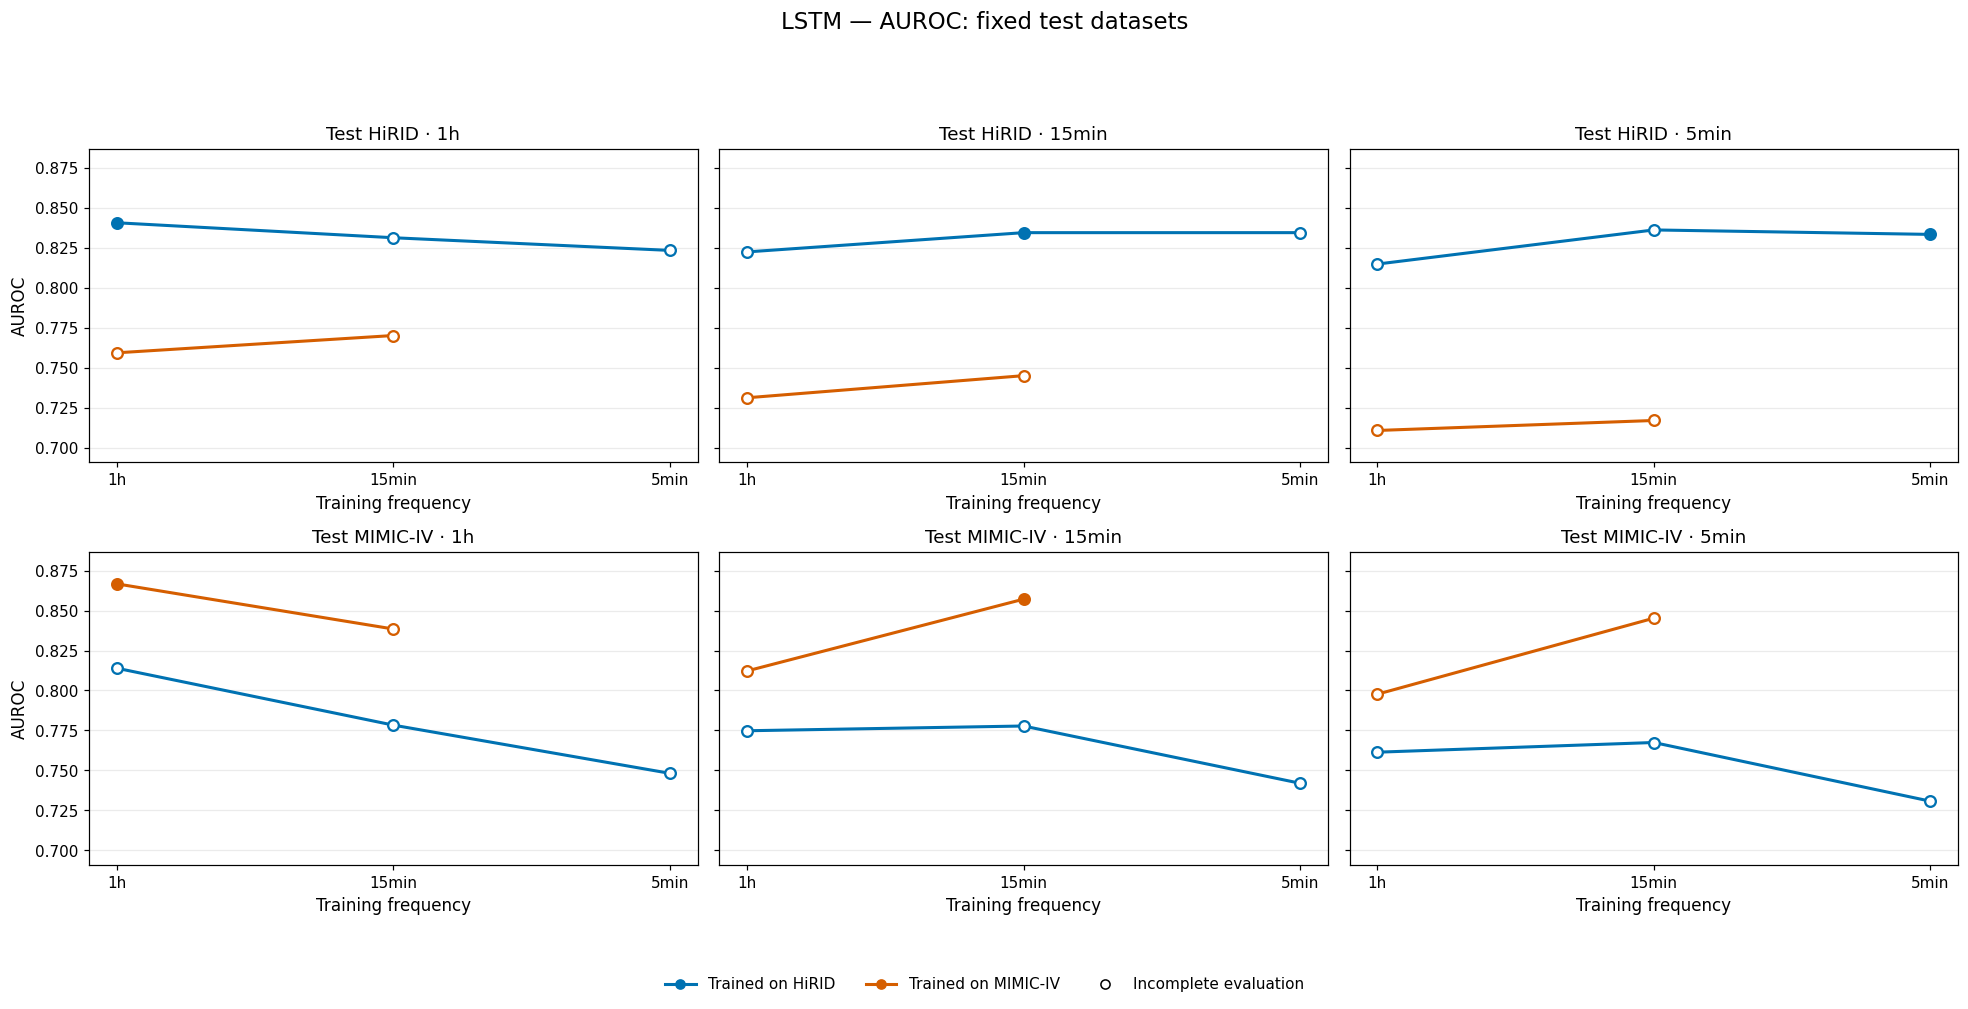

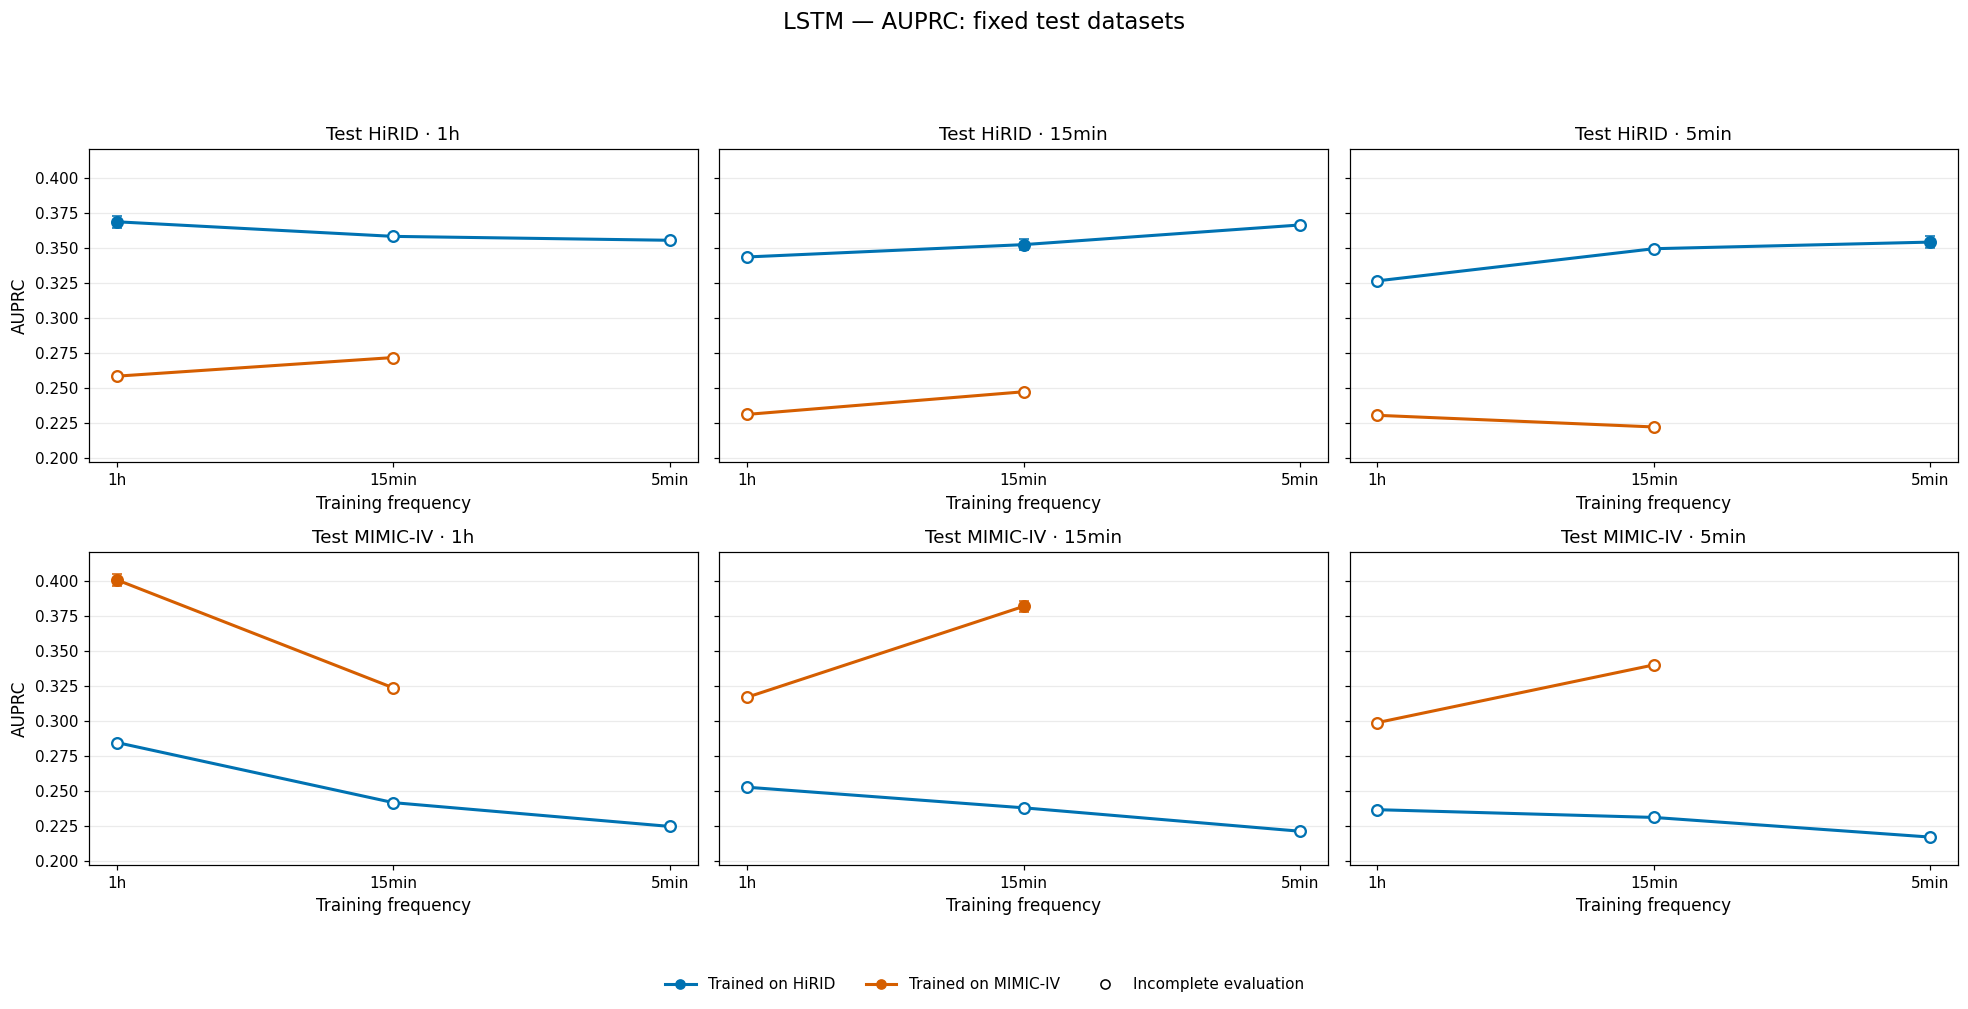

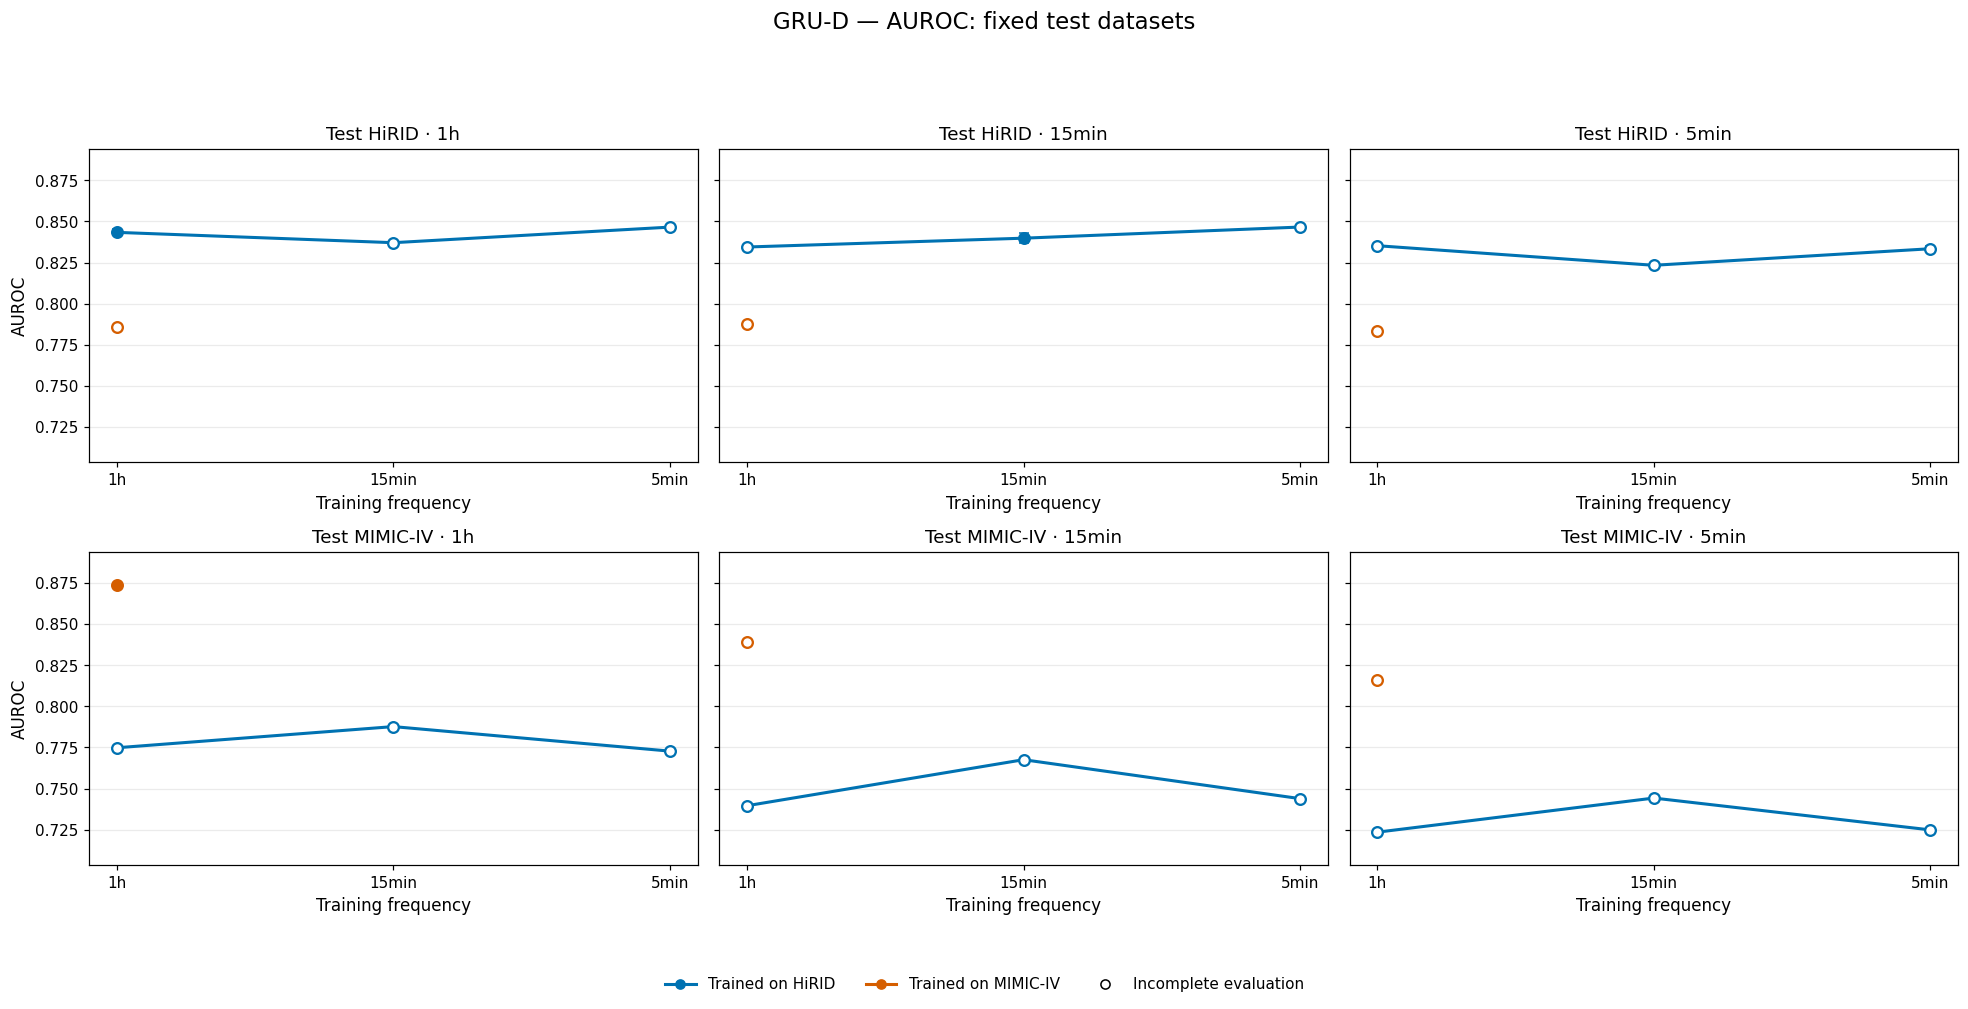

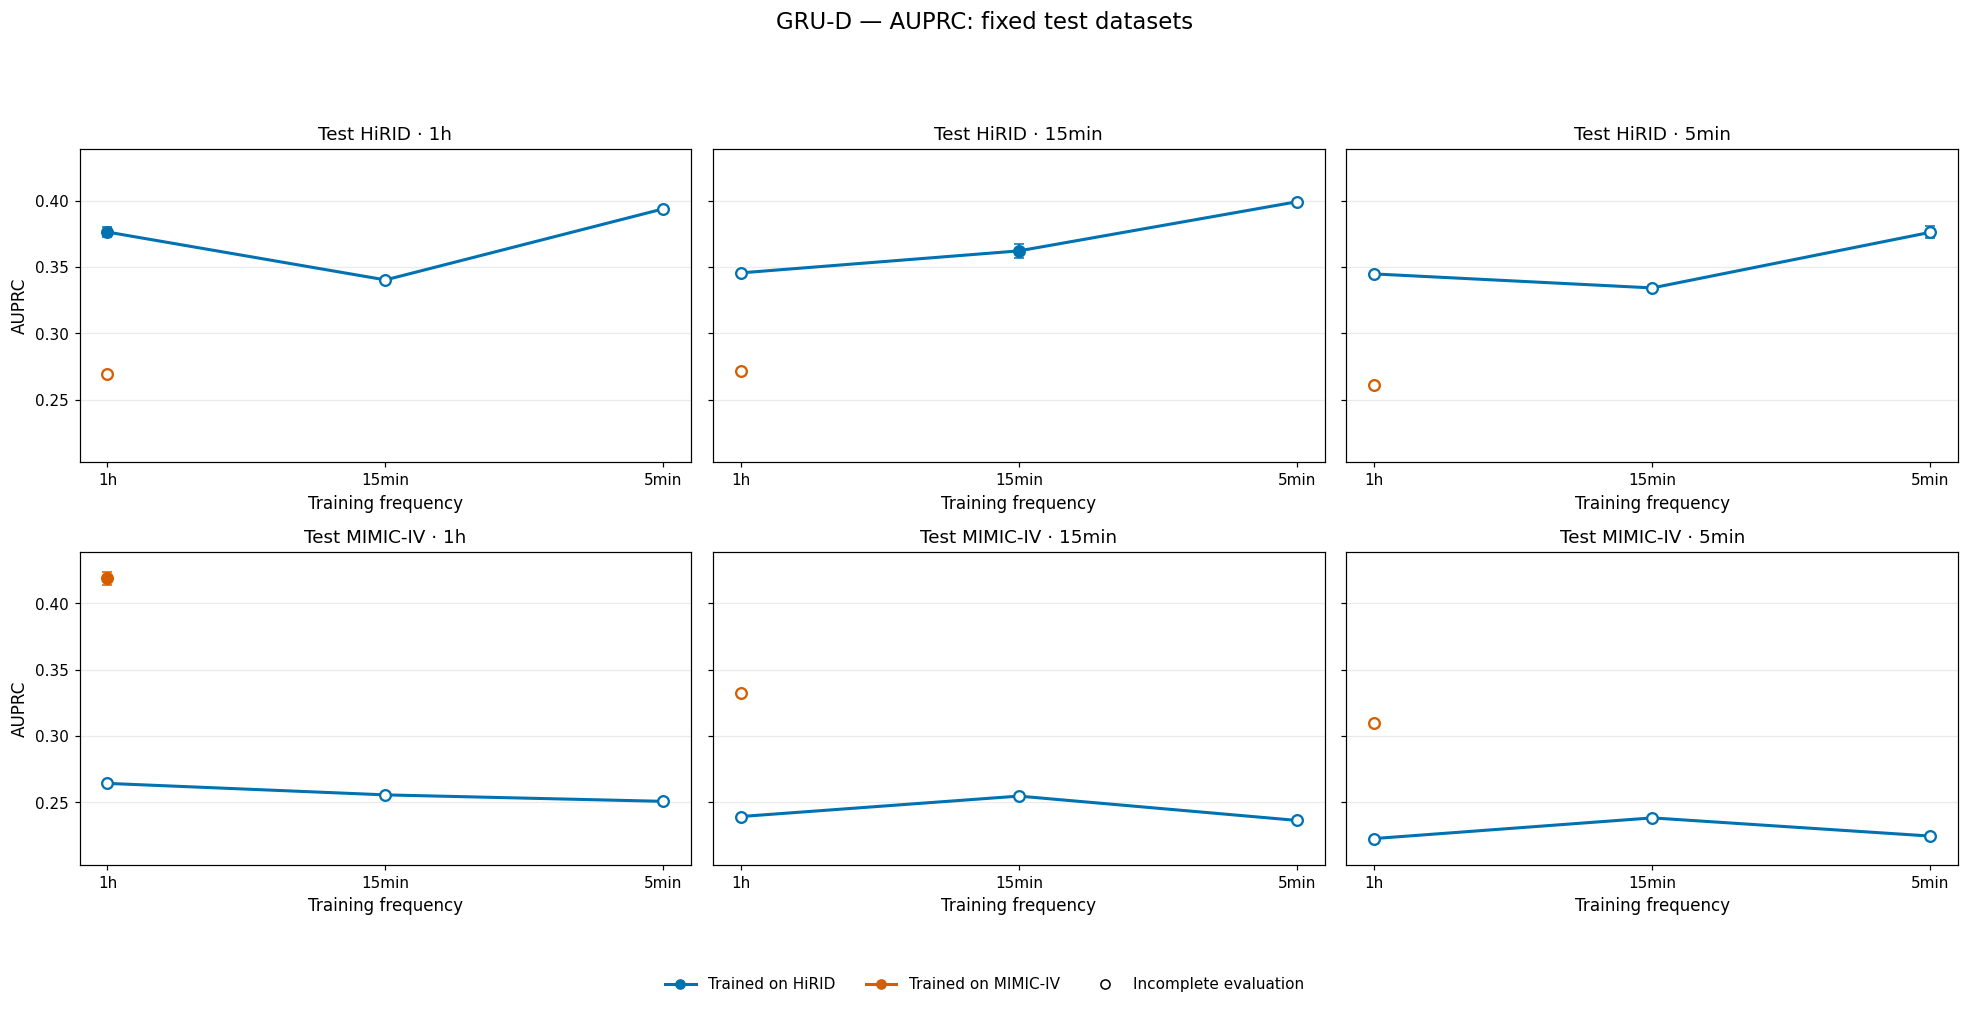

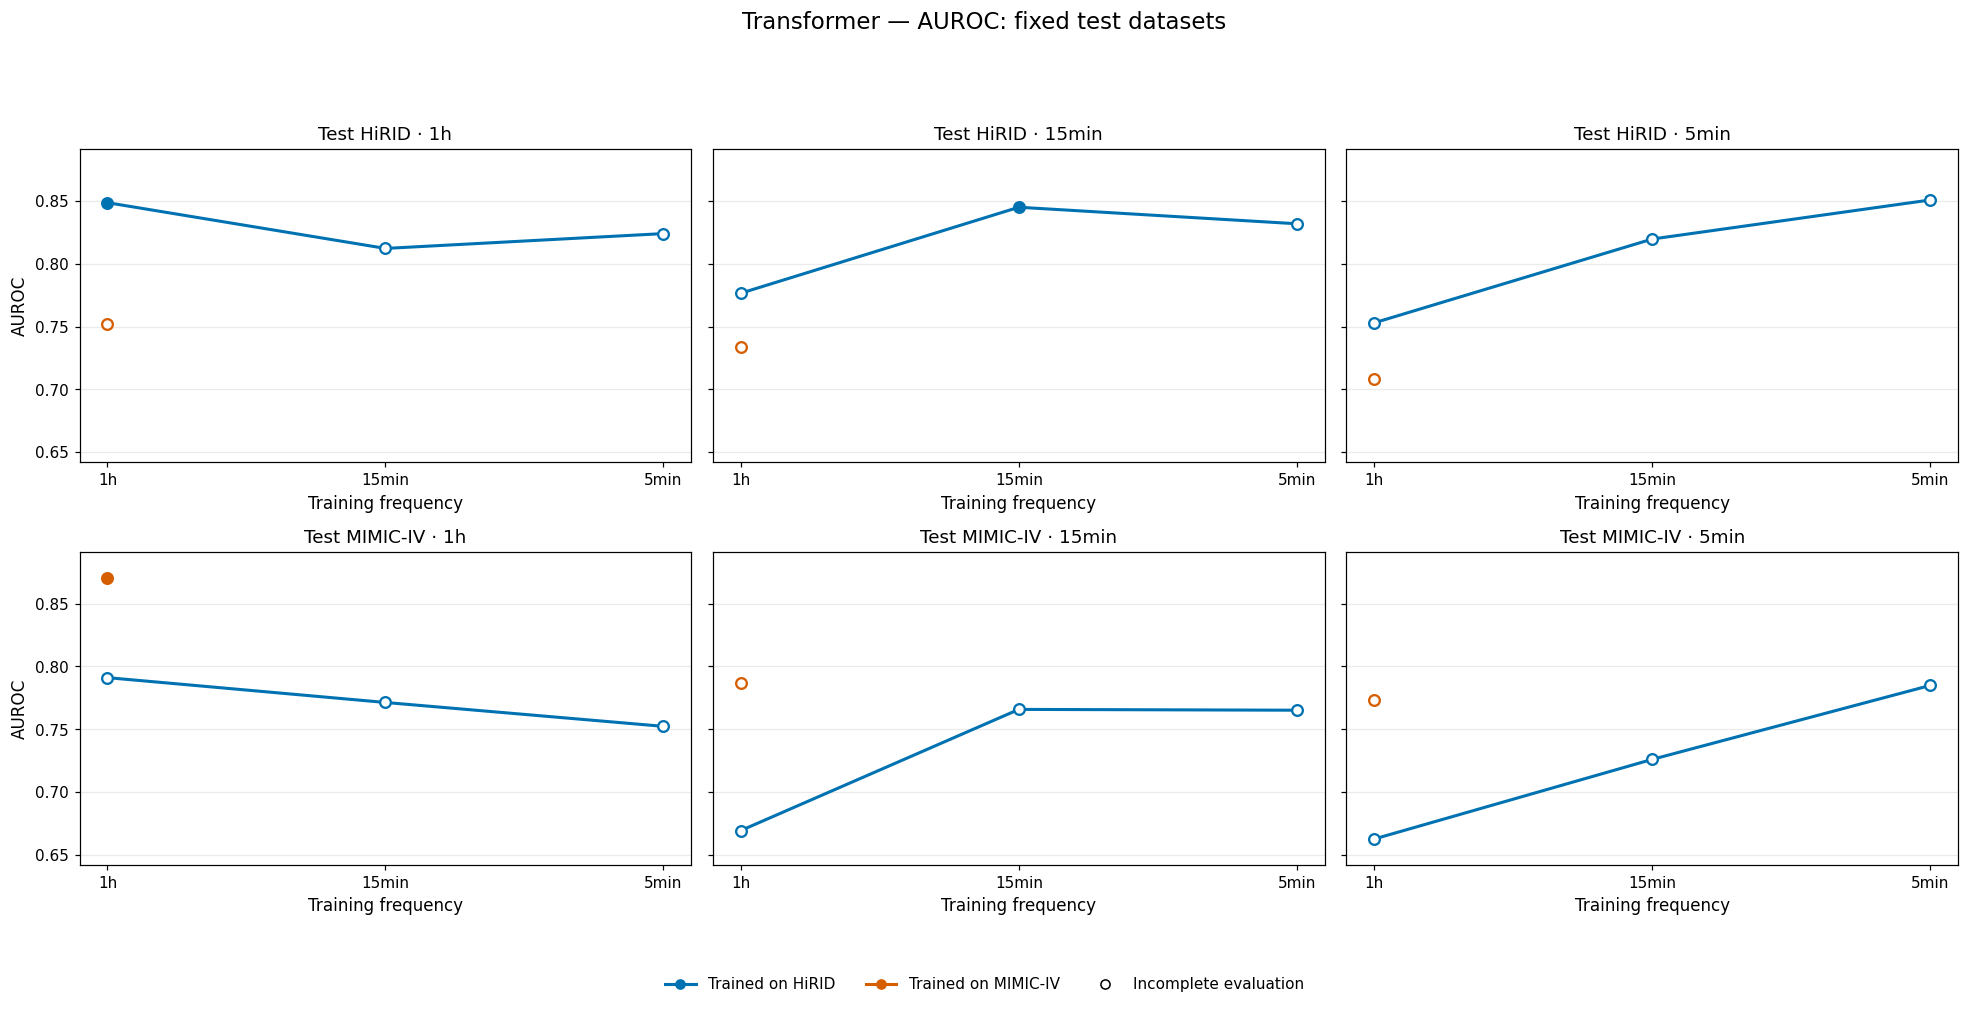

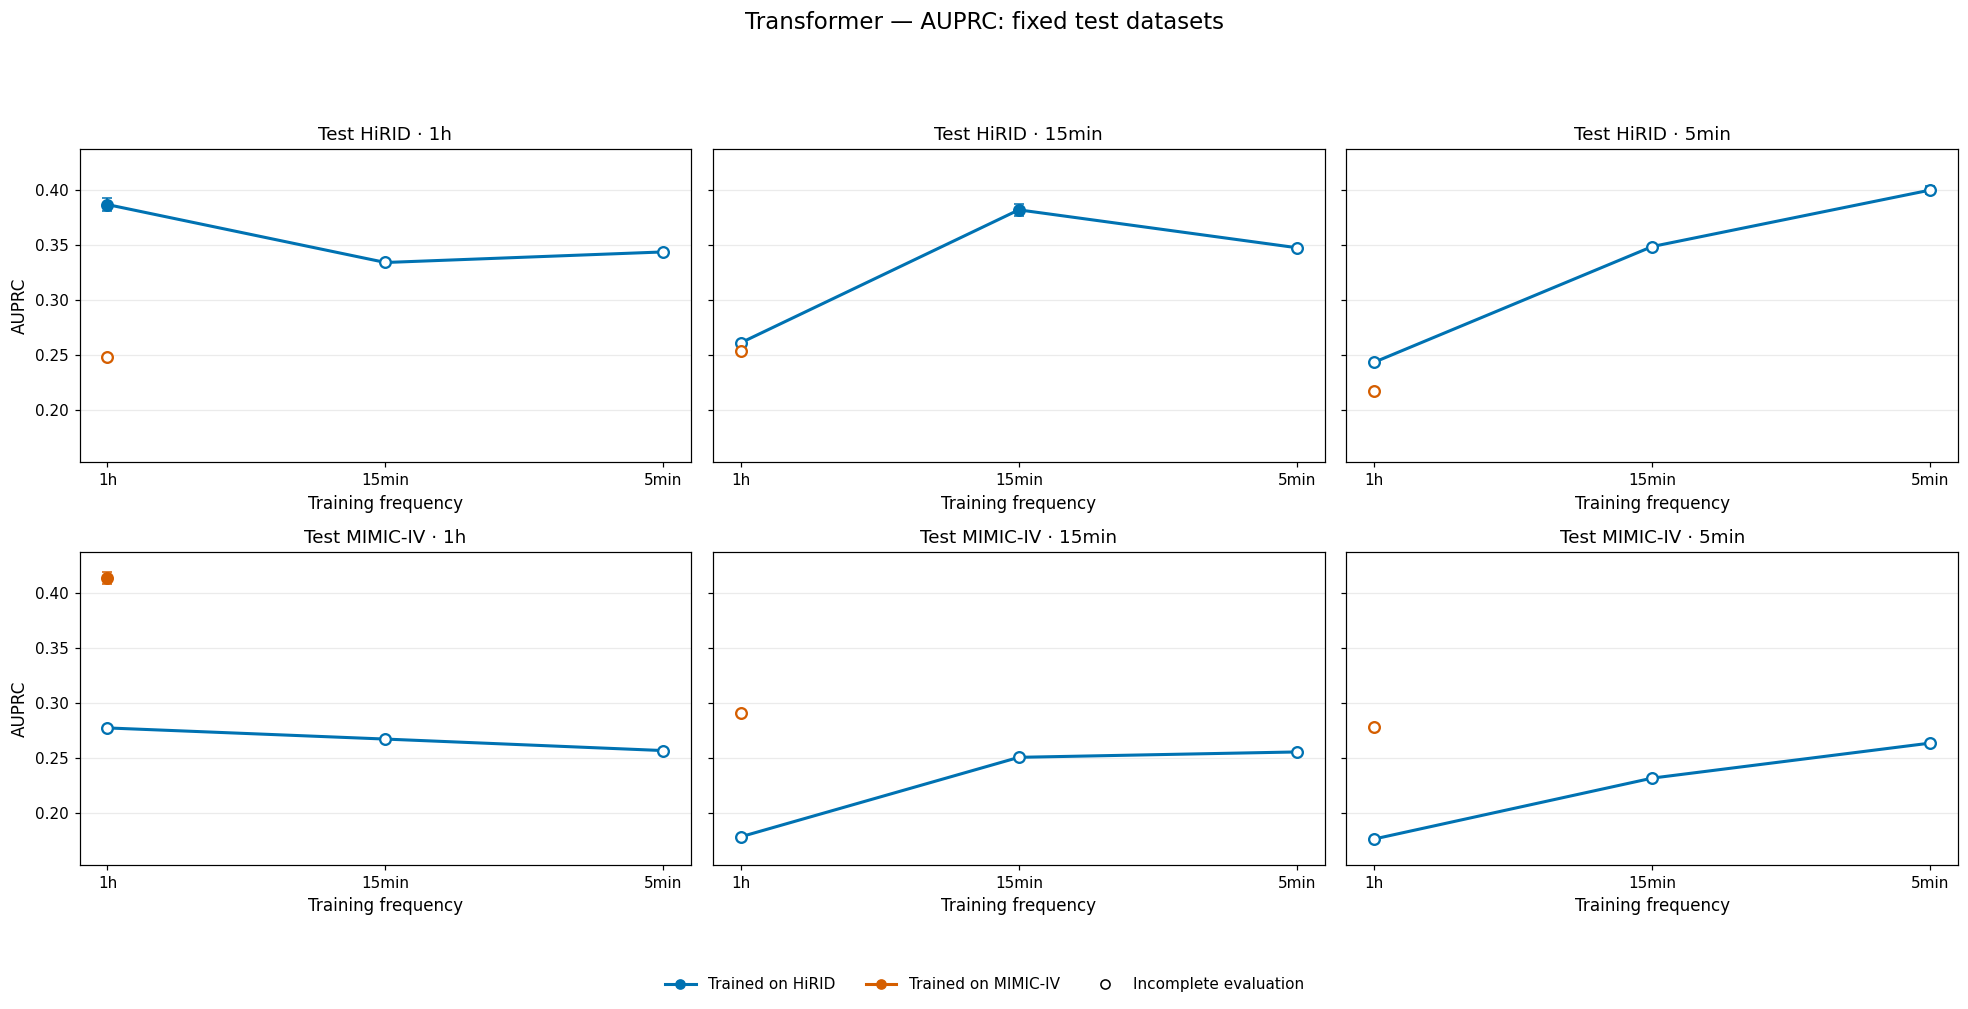

In [6]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SAVED_FIGURES = []

def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches='tight')
    SAVED_FIGURES.append(path)
    return path

def metric_limits(model_key, metric_key):
    column = METRICS[metric_key][1] + ' mean'
    values = results_df.loc[results_df['_model_key'] == model_key, column].dropna().to_numpy(dtype=float)
    if not len(values):
        raise ValueError(f'No values available for {model_key} {metric_key}')
    spread = max(float(values.max() - values.min()), 0.08)
    padding = max(0.02, spread * 0.10)
    low = max(0.0, float(values.min()) - padding)
    high = min(1.0, float(values.max()) + padding)
    if high - low < 0.10:
        center = (low + high) / 2
        low, high = max(0.0, center - 0.05), min(1.0, center + 0.05)
    return low, high

def rows_for(model_key, train_hospital=None, test_hospital=None, test_frequency=None):
    rows = results_df[results_df['_model_key'] == model_key]
    if train_hospital is not None:
        rows = rows[rows['Train hospital'] == train_hospital]
    if test_hospital is not None:
        rows = rows[rows['Test hospital'] == test_hospital]
    if test_frequency is not None:
        rows = rows[rows['Test frequency'] == test_frequency]
    return rows

def plot_fixed_test(model_key, metric_key):
    mean_col, metric_label = METRICS[metric_key][1] + ' mean', METRICS[metric_key][1]
    std_col = METRICS[metric_key][1] + ' std'
    fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True, squeeze=False)
    x_positions = np.arange(len(FREQUENCIES))
    for row_index, test_hospital in enumerate(HOSPITALS):
        for col_index, test_frequency in enumerate(FREQUENCIES):
            ax = axes[row_index, col_index]
            for train_hospital in HOSPITALS:
                subset = rows_for(model_key, train_hospital, test_hospital, test_frequency)
                subset = subset.set_index('Train frequency').reindex(FREQUENCIES).dropna(subset=[mean_col])
                if subset.empty:
                    continue
                color = HOSPITAL_COLORS[train_hospital]
                xs = [x_positions[FREQUENCIES.index(freq)] for freq in subset.index]
                ys = subset[mean_col].to_numpy(float)
                ax.plot(xs, ys, color=color, linewidth=2, zorder=2)
                for x, (_, point) in zip(xs, subset.iterrows()):
                    marker = 'o' if point['Complete/incomplete'] == 'Complete' else 'o'
                    face = color if point['Complete/incomplete'] == 'Complete' else 'white'
                    ax.plot(x, point[mean_col], marker=marker, color=color, markerfacecolor=face, markeredgewidth=1.5, markersize=7, zorder=3)
                    if np.isfinite(point[std_col]):
                        ax.errorbar(x, point[mean_col], yerr=point[std_col], fmt='none', ecolor=color, capsize=3, linewidth=1.2, zorder=1)
            ax.set_title(f'Test {test_hospital} · {test_frequency}')
            ax.set_xticks(x_positions, FREQUENCIES)
            ax.grid(axis='y', alpha=0.25)
            ax.set_xlabel('Training frequency')
            if col_index == 0:
                ax.set_ylabel(metric_label)
    low, high = metric_limits(model_key, metric_key)
    for ax in axes.ravel():
        ax.set_ylim(low, high)
    handles = [Line2D([0], [0], color=HOSPITAL_COLORS[h], marker='o', linewidth=2, label=f'Trained on {h}') for h in HOSPITALS]
    handles.append(Line2D([0], [0], color='black', marker='o', markerfacecolor='white', label='Incomplete evaluation', linestyle='None'))
    fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.015))
    fig.suptitle(f'{MODEL_LABELS[model_key]} — {metric_label}: fixed test datasets', y=1.02, fontsize=15)
    fig.tight_layout(rect=(0, 0.09, 1, 0.96))
    save_figure(fig, f'fixed_test_{model_key.lower()}_{metric_key.lower()}.png')
    plt.show()

for model_key in MODELS:
    for metric_key in METRICS:
        plot_fixed_test(model_key, metric_key)

## 7. Frequency-transfer heatmaps

Rows are training frequencies and columns are test frequencies. Each figure uses one color scale across all four hospital-transfer panels.

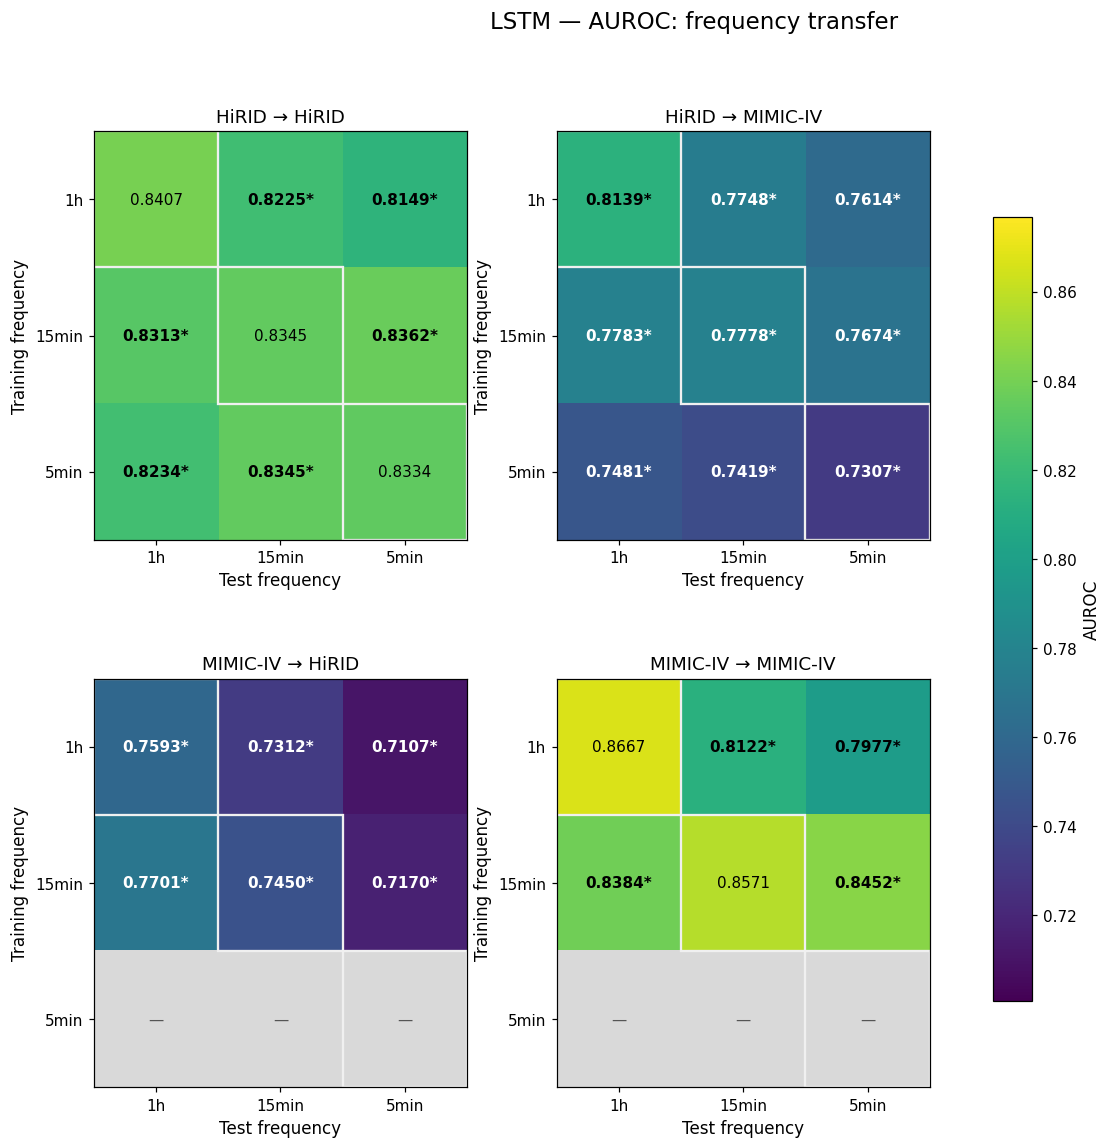

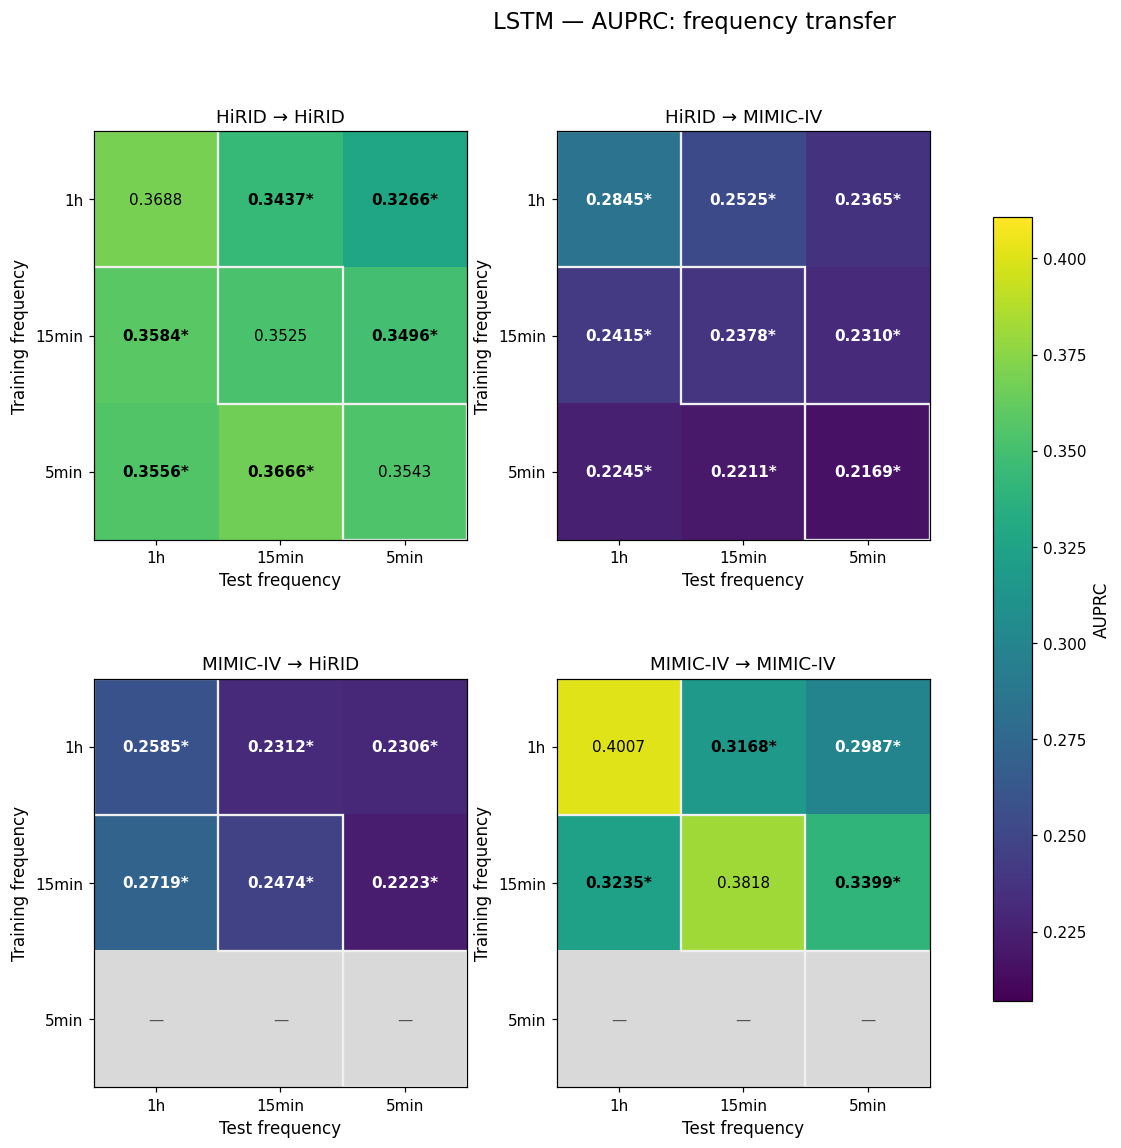

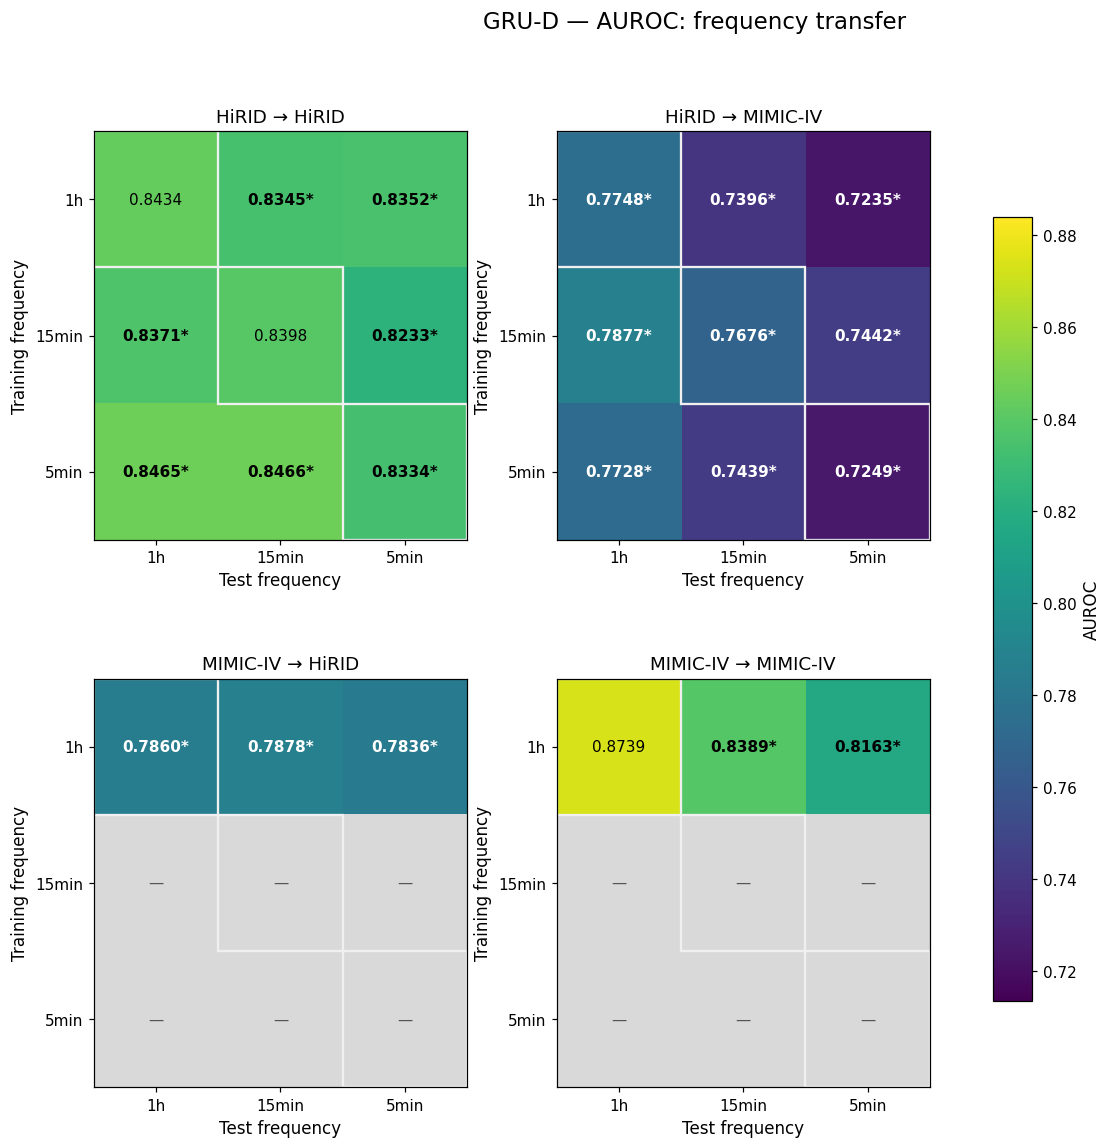

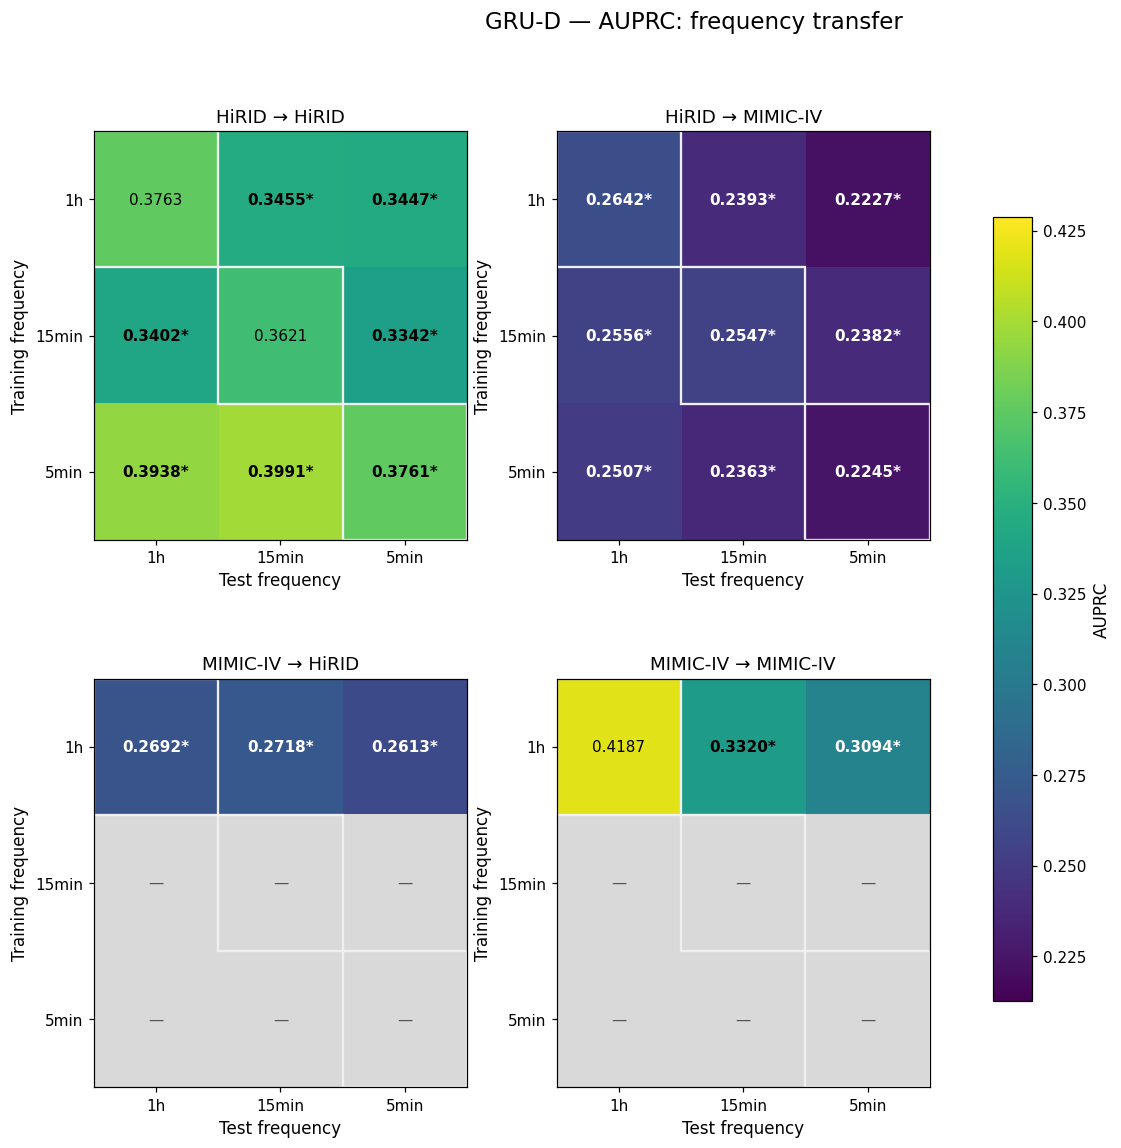

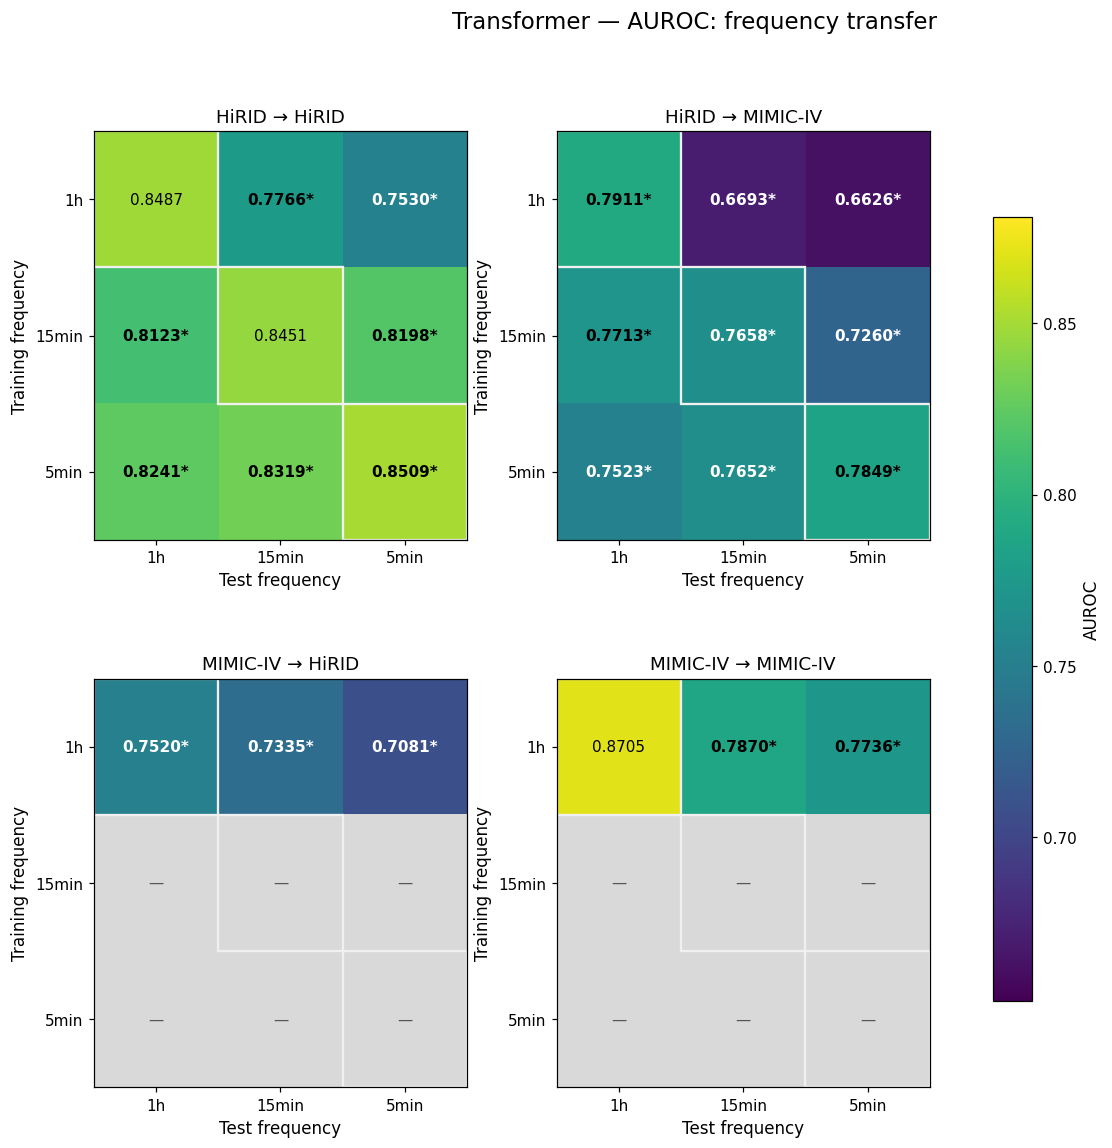

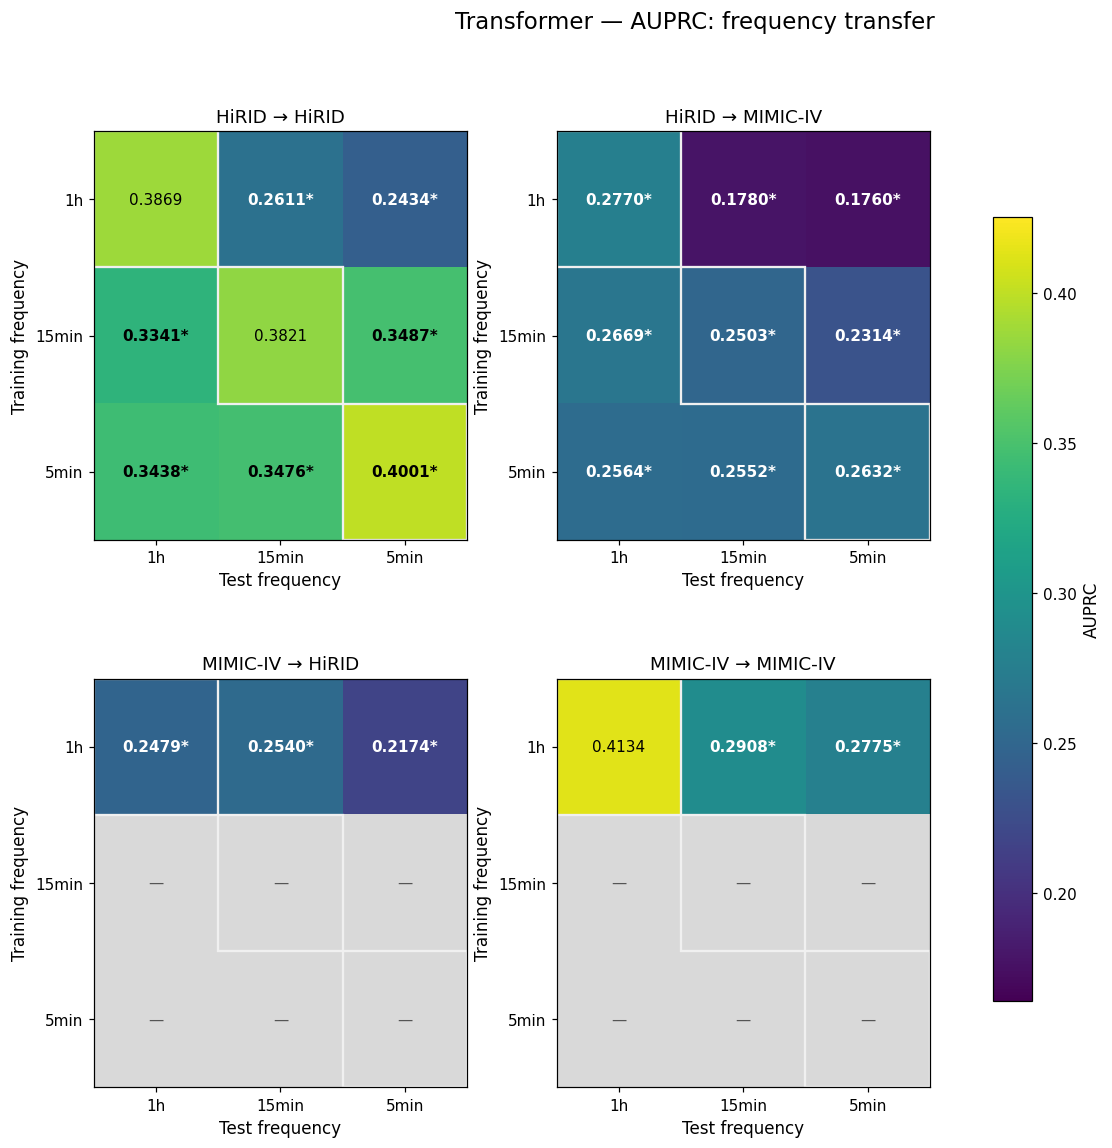

In [7]:
def heatmap_limits(model_key, metric_key):
    column = METRICS[metric_key][1] + ' mean'
    values = results_df.loc[results_df['_model_key'] == model_key, column].dropna().to_numpy(dtype=float)
    if not len(values):
        raise ValueError(f'No values available for {model_key} {metric_key}')
    span = max(float(values.max() - values.min()), 0.08)
    padding = max(0.01, span * 0.05)
    return max(0.0, float(values.min()) - padding), min(1.0, float(values.max()) + padding)

def plot_heatmaps(model_key, metric_key):
    mean_col, metric_label = METRICS[metric_key][1] + ' mean', METRICS[metric_key][1]
    vmin, vmax = heatmap_limits(model_key, metric_key)
    fig, axes = plt.subplots(2, 2, figsize=(13, 11), squeeze=False)
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('#D9D9D9')
    images = []
    for row_index, train_hospital in enumerate(HOSPITALS):
        for col_index, test_hospital in enumerate(HOSPITALS):
            ax = axes[row_index, col_index]
            matrix = np.full((3, 3), np.nan)
            incomplete = np.zeros((3, 3), dtype=bool)
            subset = results_df[(results_df['_model_key'] == model_key) & (results_df['Train hospital'] == train_hospital) & (results_df['Test hospital'] == test_hospital)]
            for _, point in subset.iterrows():
                i, j = FREQUENCIES.index(point['Train frequency']), FREQUENCIES.index(point['Test frequency'])
                matrix[i, j] = point[mean_col]
                incomplete[i, j] = point['Complete/incomplete'] == 'Incomplete'
            image = ax.imshow(np.ma.masked_invalid(matrix), cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
            images.append(image)
            threshold = (vmin + vmax) / 2
            for i in range(3):
                for j in range(3):
                    if np.isfinite(matrix[i, j]):
                        text_color = 'white' if matrix[i, j] < threshold else 'black'
                        text = f'{matrix[i, j]:.4f}' + ('*' if incomplete[i, j] else '')
                    else:
                        text, text_color = '—', '#555555'
                    ax.text(j, i, text, ha='center', va='center', color=text_color, fontsize=10, fontweight='bold' if incomplete[i, j] else 'normal')
                    ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor='#F0F0F0', linewidth=1.5 if i == j else 0.0))
            ax.set_xticks(range(3), FREQUENCIES)
            ax.set_yticks(range(3), FREQUENCIES)
            ax.set_xlabel('Test frequency')
            ax.set_ylabel('Training frequency')
            ax.set_title(f'{train_hospital} → {test_hospital}')
    fig.subplots_adjust(top=0.87, bottom=0.08, left=0.08, right=0.82, hspace=0.34, wspace=0.24)
    fig.colorbar(images[0], ax=axes.ravel().tolist(), shrink=0.82, pad=0.06, label=metric_label)
    fig.suptitle(f'{MODEL_LABELS[model_key]} — {metric_label}: frequency transfer', y=0.97, fontsize=15)
    save_figure(fig, f'frequency_transfer_{model_key.lower()}_{metric_key.lower()}.png')
    plt.show()

for model_key in MODELS:
    for metric_key in METRICS:
        plot_heatmaps(model_key, metric_key)

## 8. Model comparisons

These figures compare architectures under the same test hospital and test frequency. Rows separate the training hospital; columns separate the test frequency.

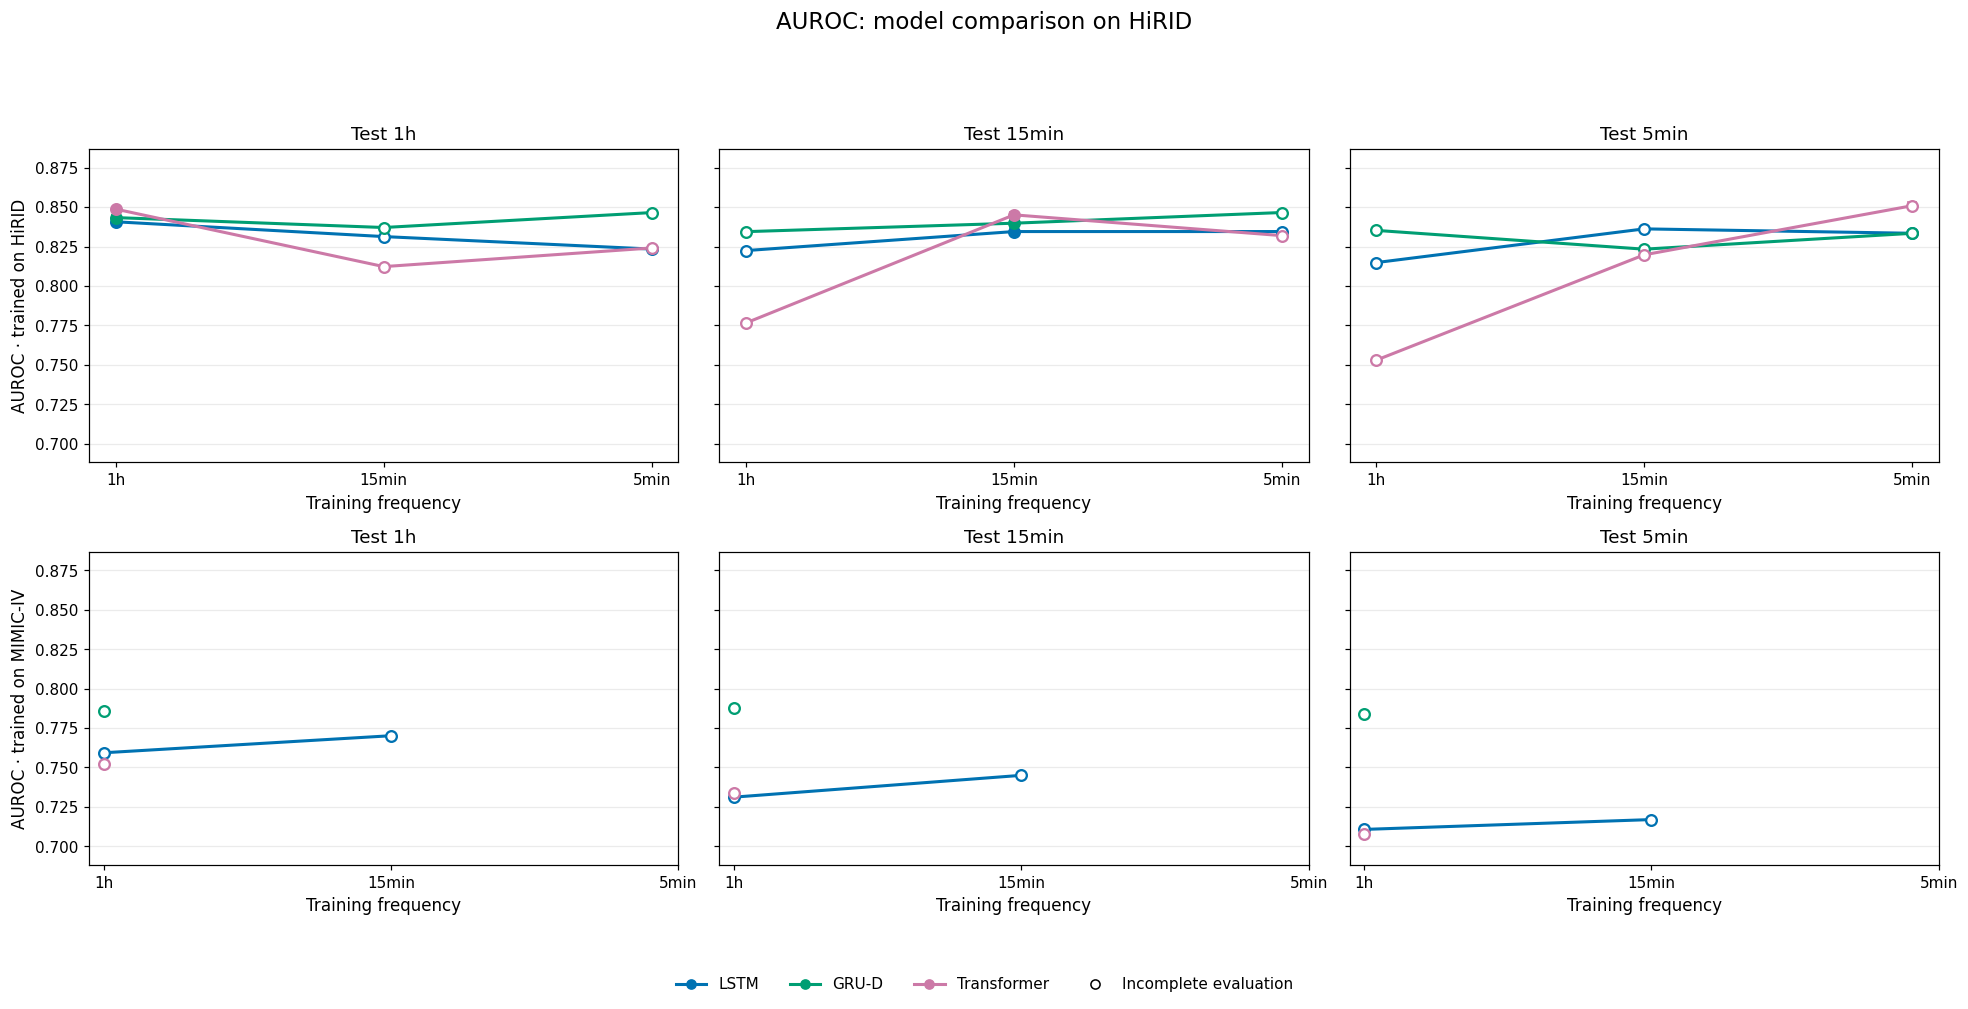

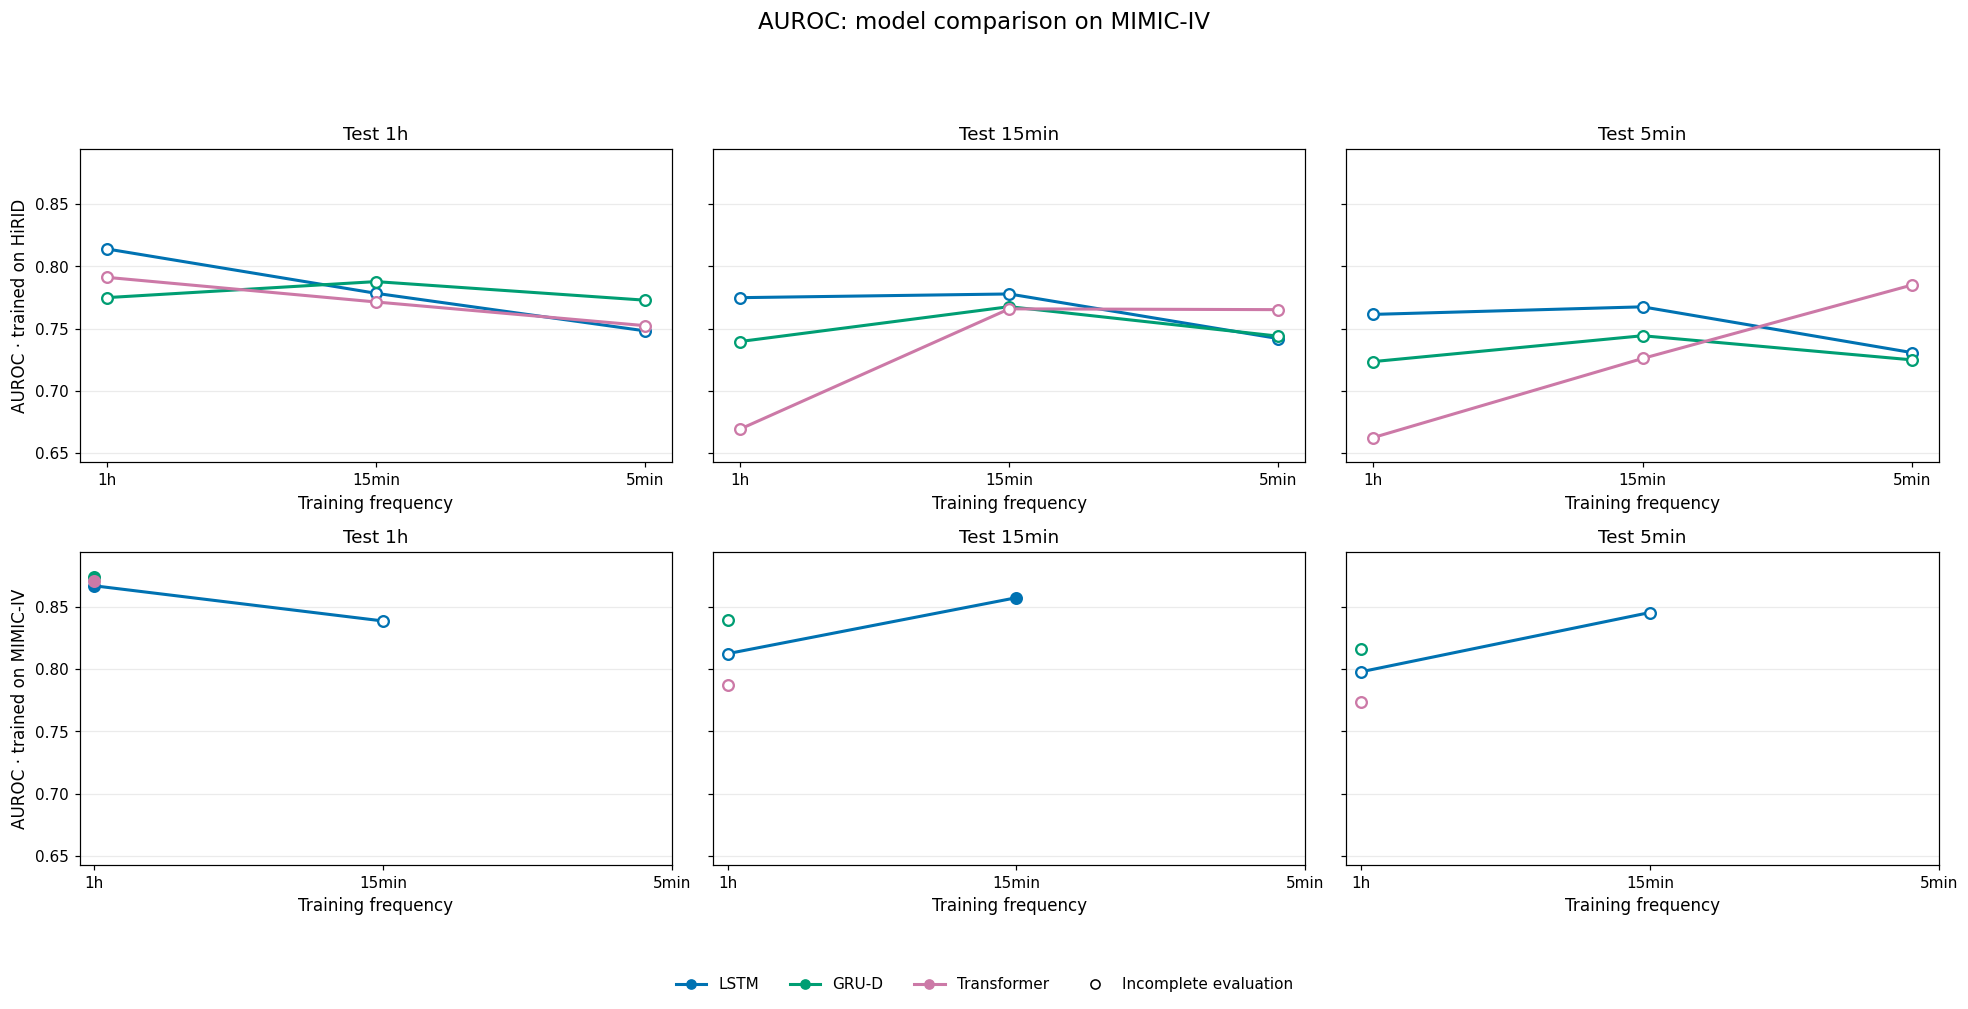

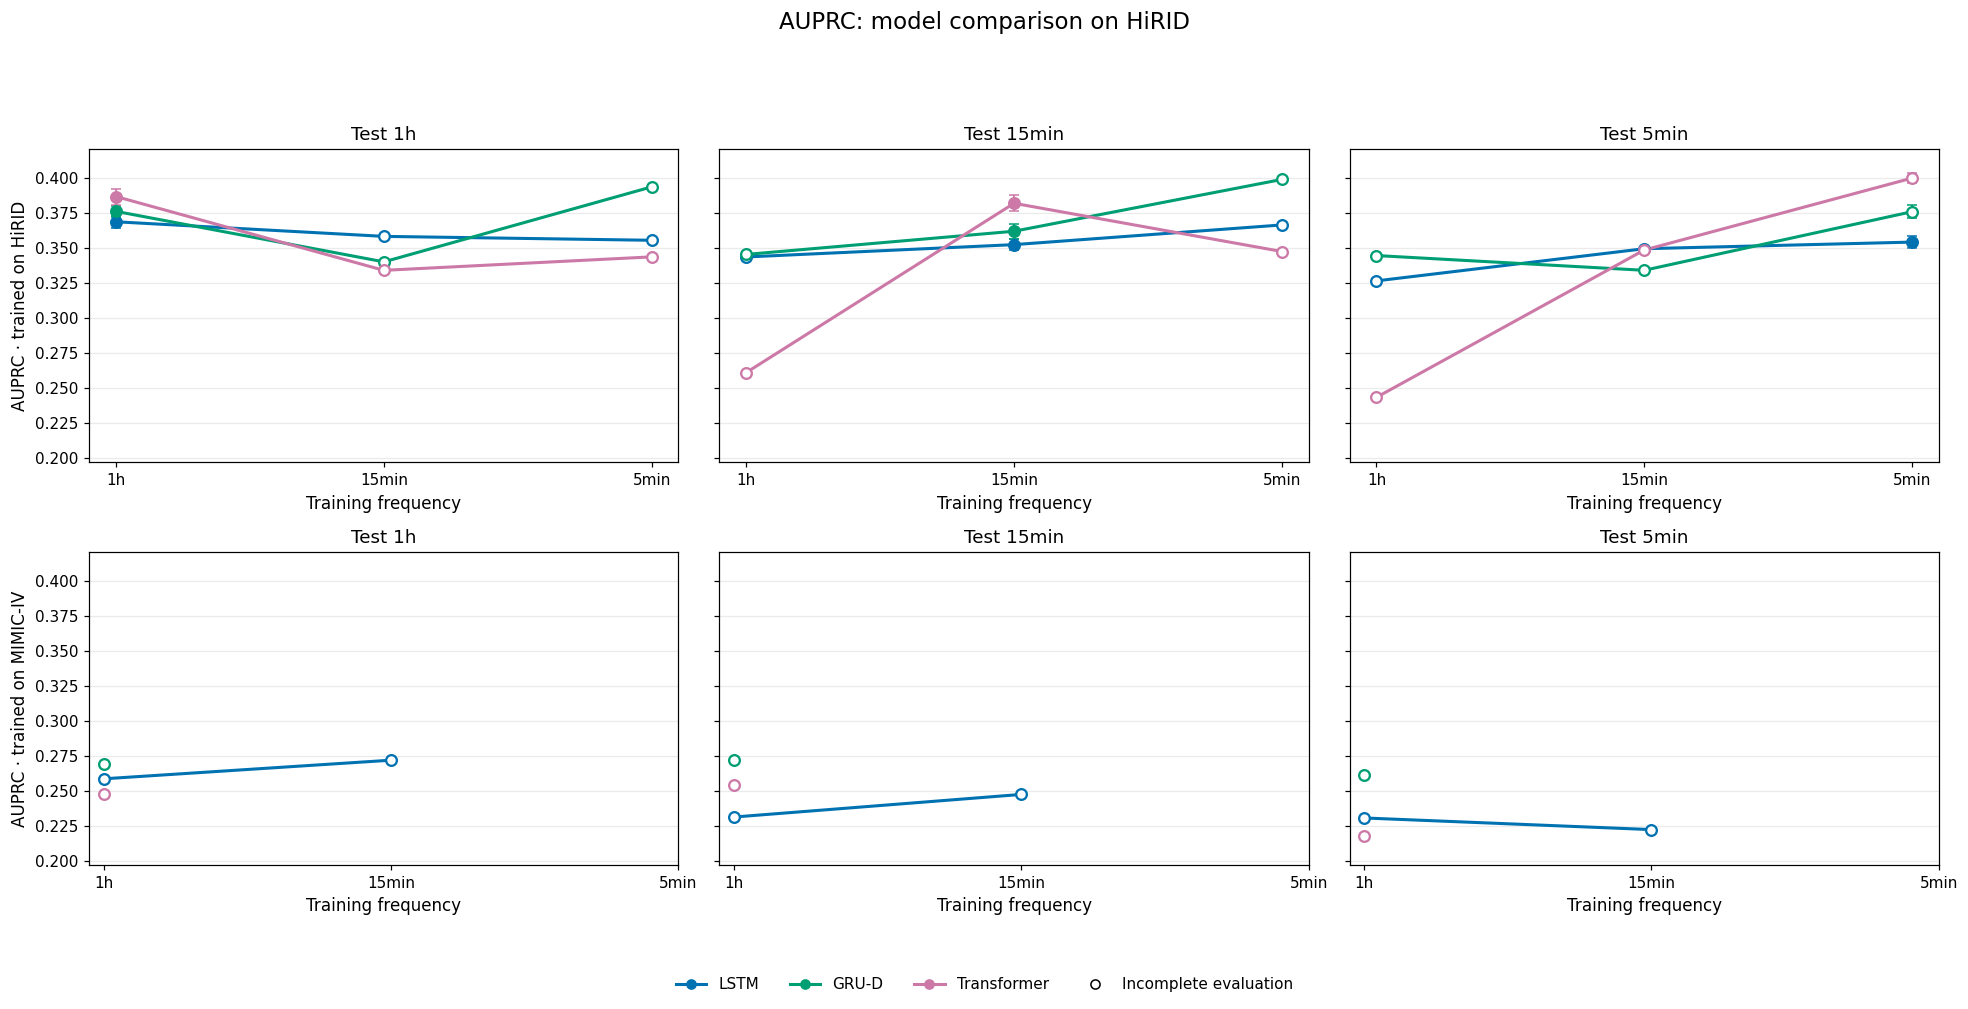

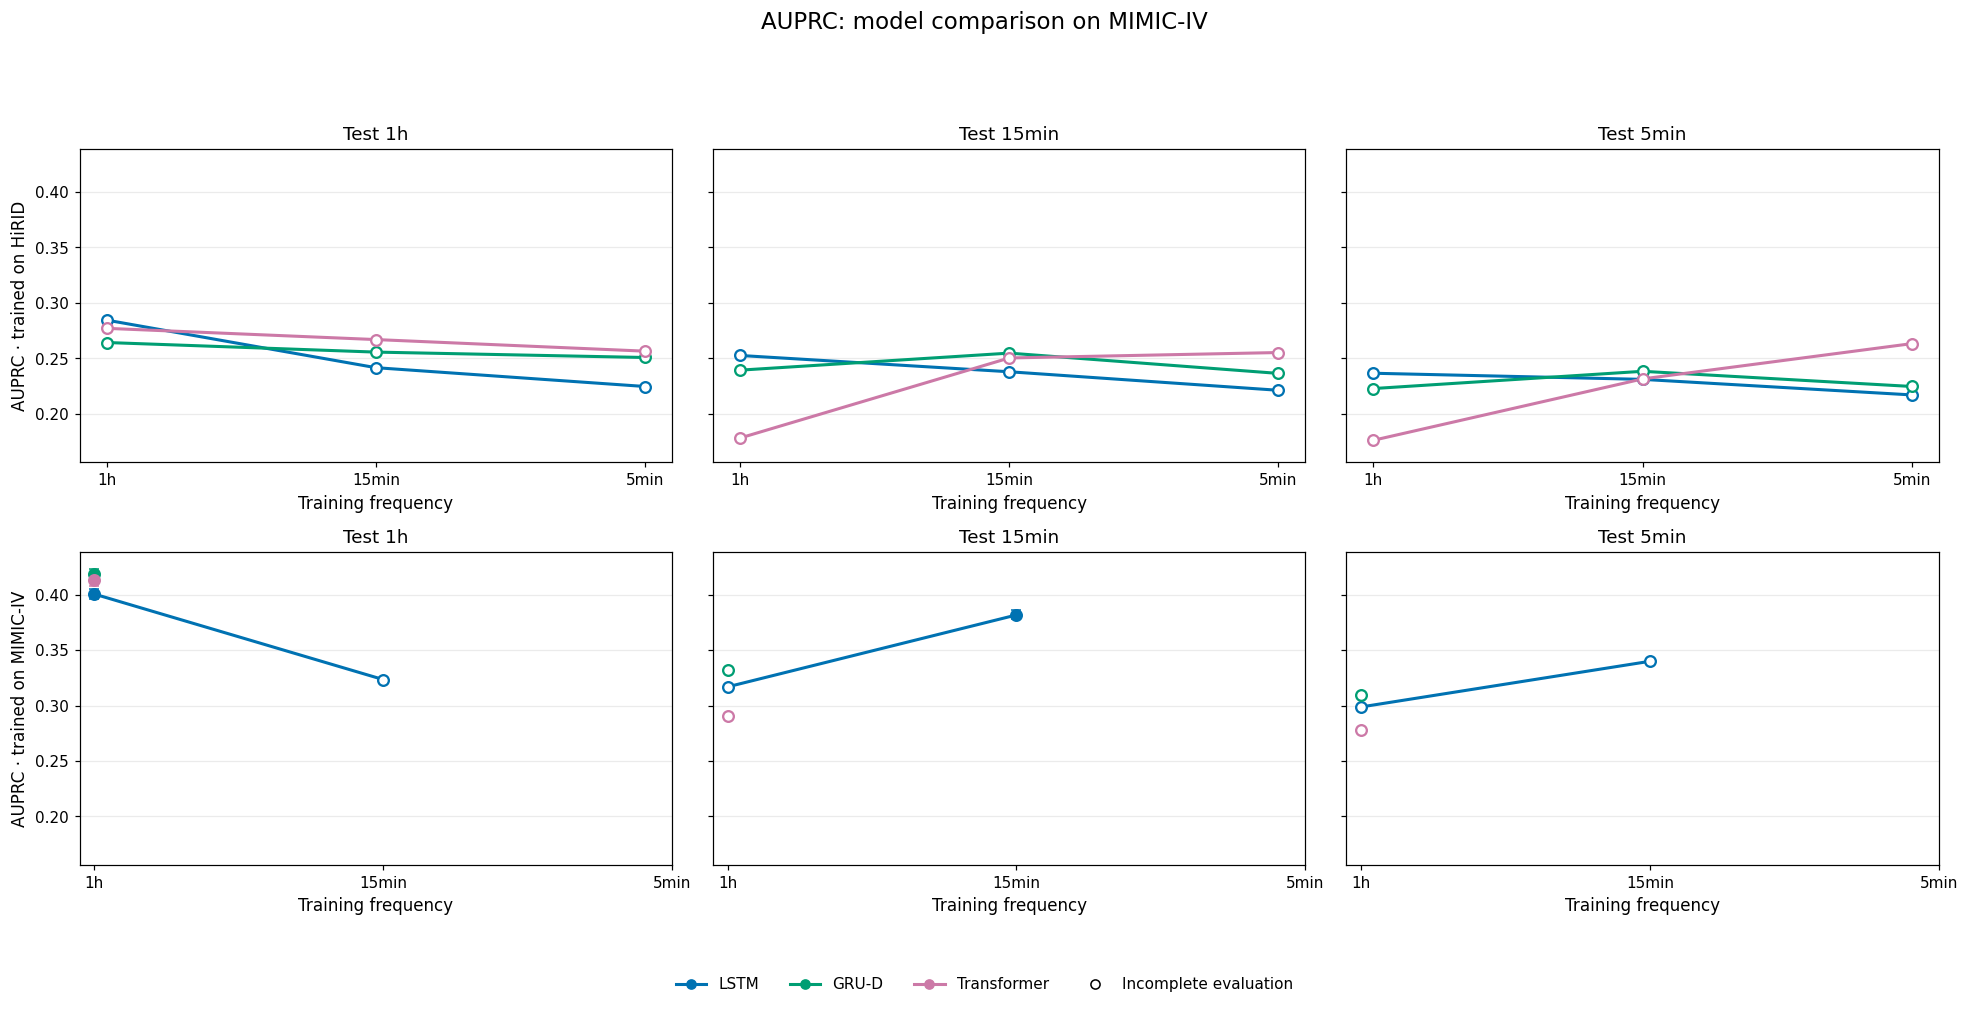

In [8]:
def plot_model_comparison(metric_key, test_hospital):
    mean_col, metric_label = METRICS[metric_key][1] + ' mean', METRICS[metric_key][1]
    std_col = METRICS[metric_key][1] + ' std'
    fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True, squeeze=False)
    x_positions = np.arange(3)
    for row_index, train_hospital in enumerate(HOSPITALS):
        for col_index, test_frequency in enumerate(FREQUENCIES):
            ax = axes[row_index, col_index]
            for model_key in MODELS:
                subset = results_df[(results_df['_model_key'] == model_key) & (results_df['Train hospital'] == train_hospital) & (results_df['Test hospital'] == test_hospital) & (results_df['Test frequency'] == test_frequency)]
                subset = subset.set_index('Train frequency').reindex(FREQUENCIES).dropna(subset=[mean_col])
                if subset.empty:
                    continue
                color = MODEL_COLORS[model_key]
                xs = [x_positions[FREQUENCIES.index(freq)] for freq in subset.index]
                ax.plot(xs, subset[mean_col].to_numpy(float), color=color, linewidth=2, zorder=2)
                for x, (_, point) in zip(xs, subset.iterrows()):
                    face = color if point['Complete/incomplete'] == 'Complete' else 'white'
                    ax.plot(x, point[mean_col], marker='o', color=color, markerfacecolor=face, markeredgewidth=1.5, markersize=7, zorder=3)
                    if np.isfinite(point[std_col]):
                        ax.errorbar(x, point[mean_col], yerr=point[std_col], fmt='none', ecolor=color, capsize=3, linewidth=1.2, zorder=1)
            ax.set_title(f'Test {test_frequency}')
            ax.set_xticks(x_positions, FREQUENCIES)
            ax.set_xlabel('Training frequency')
            ax.grid(axis='y', alpha=0.25)
            if col_index == 0:
                ax.set_ylabel(f'{metric_label} · trained on {train_hospital}')
    low, high = metric_limits('LSTM', metric_key)
    all_values = results_df[results_df['Test hospital'] == test_hospital][mean_col].dropna()
    if len(all_values):
        low = max(0.0, min(low, float(all_values.min()) - 0.02))
        high = min(1.0, max(high, float(all_values.max()) + 0.02))
    for ax in axes.ravel():
        ax.set_ylim(low, high)
    handles = [Line2D([0], [0], color=MODEL_COLORS[m], marker='o', linewidth=2, label=MODEL_LABELS[m]) for m in MODELS]
    handles.append(Line2D([0], [0], color='black', marker='o', markerfacecolor='white', label='Incomplete evaluation', linestyle='None'))
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.015))
    fig.suptitle(f'{metric_label}: model comparison on {test_hospital}', y=1.02, fontsize=15)
    fig.tight_layout(rect=(0, 0.09, 1, 0.96))
    save_figure(fig, f'model_comparison_{metric_key.lower()}_{test_hospital.lower().replace("-", "_")}.png')
    plt.show()

for metric_key in METRICS:
    for test_hospital in HOSPITALS:
        plot_model_comparison(metric_key, test_hospital)

## 9. Findings and limitations

The figures show absolute AUROC and AUPRC for the selected final runs. Missing cells and points indicate unavailable experiment configurations; they are not zero-performance results. Asterisks and hollow markers identify incomplete evaluations. Error bars use YAIB's stored standard deviations and should not be interpreted as significance tests. Differences between curves are descriptive and may reflect incomplete coverage, run-to-run variation, or hospital and frequency shifts.